In [2]:
import pandas as pd
from astropy.io import fits
import numpy as np
from astropy.table import Table
import matplotlib.pyplot as plt
import subprocess
import os
from math import sin, cos, tan, radians, sqrt, pi
from os.path import join
from matplotlib.pylab import *
from scipy import stats
from scipy.stats import ks_2samp
import seaborn as sns

In [470]:
# Initialisation and parameters
# Defines inputs
# Run fearlessly

cat_csv = pd.read_csv("/Users/kyriakos.trakakis/Downloads/Other_Stuff/ATLASGAL_CSC_distances.csv")  # Example CSV

cat_csv = cat_csv[
    (cat_csv['gal_long_peak'] >= 250) & 
    (cat_csv['gal_long_peak'] <= 355)
].reset_index(drop=True)

region       = "350-355"
isotopologue = "12CO"
v_lim        = 3
v_lim2       = 5
minor_lim    = 120
# This version does not have SNR limits since there are no noise maps for Mopra

mult_path = "/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/Mopra/12CO/"

cat_csv['V_lsr'] = pd.to_numeric(cat_csv['V_lsr'], errors='coerce')
cat_csv = cat_csv.dropna(subset=['gal_long_peak', 'gal_lat_peak', 'V_lsr']).reset_index(drop=True)

input_filename  = f"G{region}-13CO_smallercube_05res_min_del_2_parallel_clusters.fits"
mult_filename   = mult_path +f"G{region}-{isotopologue}_smallercube_05res.fits"
COLTE_N13_file  = f"/Users/kyriakos.trakakis/COLTE/colte_G{region}_smallercube_05res_snr3_N13CO.fits"

clusters_path     = "/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/Mopra/13CO/"
clusters_file     = f"G{region}-13CO_smallercube_05res_min_del_2_parallel_clusters_table.fits"
csv_output        = mult_path +f"G{region}-{isotopologue}_X_factor_masses.csv"
table             = Table.read(clusters_path + clusters_file, format='fits')

df = table.to_pandas()

# --- Load original data ---
with fits.open(os.path.join(clusters_path, input_filename)) as hdul:
    data = hdul[0].data
    header = hdul[0].header
    
CDELT3 = header['CDELT3']

if CDELT3 < 500:
    df = df[(df["minor_arcsec"] > minor_lim / 2.354) & (df["sigv_kms"] > v_lim / 2.354)]
else:
    df = df[(df["minor_arcsec"] > minor_lim / 2.354) & (df["v_rms"] > v_lim / 2.354)]

l_atlasgal = cat_csv['gal_long_peak']
b_atlasgal = cat_csv['gal_lat_peak']
v_atlasgal = cat_csv['V_lsr']
d_atlasgal = cat_csv['distance']


# FITS (GRS) example
l_mopra = df['x_cen']
b_mopra = df['y_cen']
v_mopra = df['v_cen'] / 1000
angle = df['position_angle']

dl = np.maximum(df['major_arcsec'] / 3600 * abs(np.cos(angle*np.pi/180)), df['minor_arcsec'] * abs(np.sin(angle*np.pi/180)) / 3600) / 2 * 2.354
db = np.maximum(df['major_arcsec'] / 3600 * abs(np.sin(angle*np.pi/180)), df['minor_arcsec'] * abs(np.cos(angle*np.pi/180)) / 3600) / 2 * 2.354
dv = df['sigv_kms'] / 2 * 2.354  # Or define your own constant window like ±1 km/s

In [471]:
# Runs section 1, Atlasgal matcher rectangles
# Saves an output

# --- Match sources ---
matches = []

for i in range(len(df)):
    for j in range(len(cat_csv)):
        if (abs(l_atlasgal.iloc[j] - l_mopra.iloc[i]) <= dl.iloc[i] and
            abs(b_atlasgal.iloc[j] - b_mopra.iloc[i]) <= db.iloc[i] and
            abs(v_atlasgal.iloc[j] - v_mopra.iloc[i]) <= dv.iloc[i]):
            matches.append({
                'mopra_index': df['_idx'].iloc[i],
                'atlasgal_name': cat_csv['atlas_name'].iloc[j],  # or gname_jps
                'l_atlasgal': l_atlasgal.iloc[j],
                'b_atlasgal': b_atlasgal.iloc[j],
                'v_atlasgal': v_atlasgal.iloc[j],
                'l_mopra': round(l_mopra.iloc[i],2),
                'b_mopra': round(b_mopra.iloc[i],2),
                'v_mopra': round(v_mopra.iloc[i],2),
                'l_distance': round((l_atlasgal.iloc[j] - l_mopra.iloc[i]) / dl.iloc[i],2),
                'b_distance': round((b_atlasgal.iloc[j] - b_mopra.iloc[i]) / db.iloc[i],2),
                'v_distance': round((v_atlasgal.iloc[j] - v_mopra.iloc[i]) / dv.iloc[i],2),
                'distance': d_atlasgal.iloc[j]
            })

# Now extract all matched _idx values
matched_ids = {match['mopra_index'] for match in matches}

# Add a 'has_match' column to df
df['has_match'] = df['_idx'].isin(matched_ids)

df_matches = pd.DataFrame(matches)
print(df_matches)
#df_matches.to_csv("FGN_37_47_matched_sources_test.csv", index=False)

if df_matches.empty:
    most_common_distances = pd.DataFrame(columns=['mopra_index','most_common_distance'])
else:
    most_common_distances = (
        df_matches.groupby('mopra_index')['distance']
        .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
        .reset_index()
        .rename(columns={'distance': 'most_common_distance'})
    )

#most_common_distances = (
#    df_matches.groupby('mopra_index')['distance']
#    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
#    .reset_index()
#    .rename(columns={'distance': 'most_common_distance'})
#)

print(most_common_distances)

# Merge most_common_distance into the main DataFrame on 'mopra_index' and '_idx'
df = df.merge(most_common_distances, how='left', left_on='_idx', right_on='mopra_index')

# Fill NaN (i.e., unmatched sources) with 0
df['AGAL_distance'] = df['most_common_distance'].fillna(0)

# Optionally drop the 'mopra_index' and 'most_common_distance' columns if not needed
df = df.drop(columns=['mopra_index', 'most_common_distance'])


     mopra_index       atlasgal_name  l_atlasgal  b_atlasgal  v_atlasgal  \
0            391  AGAL351.534-00.356     351.534      -0.356       -95.0   
1            391  AGAL351.541-00.361     351.541      -0.361       -94.6   
2            391  AGAL351.581-00.352     351.581      -0.352       -93.7   
3            391  AGAL351.604-00.342     351.604      -0.342       -95.7   
4            709  AGAL352.096-00.121     352.096      -0.121       -86.6   
..           ...                 ...         ...         ...         ...   
296         9261  AGAL354.459+00.404     354.459       0.404         3.2   
297         9261  AGAL354.498+00.432     354.498       0.432         2.6   
298         9261  AGAL354.533+00.299     354.533       0.299         2.3   
299        10096  AGAL354.769+00.394     354.769       0.394        96.6   
300        10096  AGAL354.778+00.369     354.778       0.369        94.1   

     l_mopra  b_mopra  v_mopra  l_distance  b_distance  v_distance distance  
0     351

In [472]:
# Convert to Pandas DataFrame and add distance inputs
# Run fearlessly


cluster_ids = df['_idx']
cluster_ids = cluster_ids.to_numpy()

df_inp = pd.DataFrame({
    'Source'       : df['_idx'],
    'Long (deg)'   : df['x_cen'],
    'Lat (deg)'    : df['y_cen'],
    'vlsr (km/s)'  : df['v_cen']/1000,
    'v_rms (km/s)' : df['v_rms']/1000,
    'P': 0.5
})

In [473]:
# Creates the sources.info file in v2.4.1
# Saves necessary file

# Save to .inp file with space-separated columns
output_path = '/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/'
output_file = 'sources_info.inp'

with open(output_path+output_file, 'w') as f:
    f.write('! Source Long(deg) Lat(deg) vlsr(km/s) v_rms(km/s) P\n')  # comment line
    df_inp.to_csv(f, sep=' ', index=False, header=False, float_format='%.4f')


# Path to the Fortran executable
exe_path = "/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/distance_calculator"
distance_dir='/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/'
os.chdir(distance_dir)

try:
    result = subprocess.run([exe_path], check=True, capture_output=True, text=True)
    print("Program output:")
    print(result.stdout)
except subprocess.CalledProcessError as e:
    print("Error running Fortran program:")
    print(e.stderr)

Program output:
 Bayesian distance estimator: 2019: September 24, 2019

 Reading in file "probability_controls.inp                        "
 Max Prob_SA = 0.85
 Max Prob_KD = 0.85
 Max Prob_GL = 0.85
 Max Prob_PS = 0.15
 Max Prob_PM = 0.85


 Openning input ascii file "galaxy_data_Univ.inp            "
 Comment lines follow:
 ! Galactic and Solar Motion parameters                                          
 ! for use with 2-parameter Persic "Universal" rotation curve                    
 End of Comment lines

 Galaxy model:
  Ro, a1, a2, a3:                         8.15   236.000     0.960     1.620
  Solar Motion (Uo,Vo,Wo):               10.60     10.70      7.60
  Source Peculiar Motion (Us,Vs,Ws):      0.00      0.00      0.00

 Getting Spiral arm segment data:
 

  Read file Out_lbvRBD.2019      containing 176 (l,b,v,R,beta,D) values.
       Spanning longitude range:    0.0 to  252.0 deg.

  Read file Per_lbvRBD.2019      containing 272 (l,b,v,R,beta,D) values.
       Spanning long

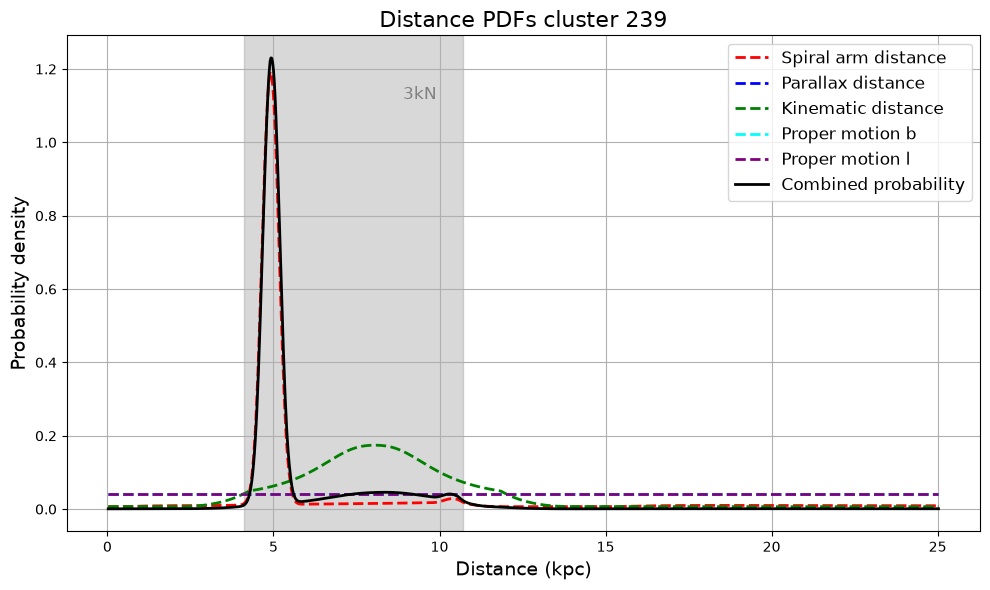

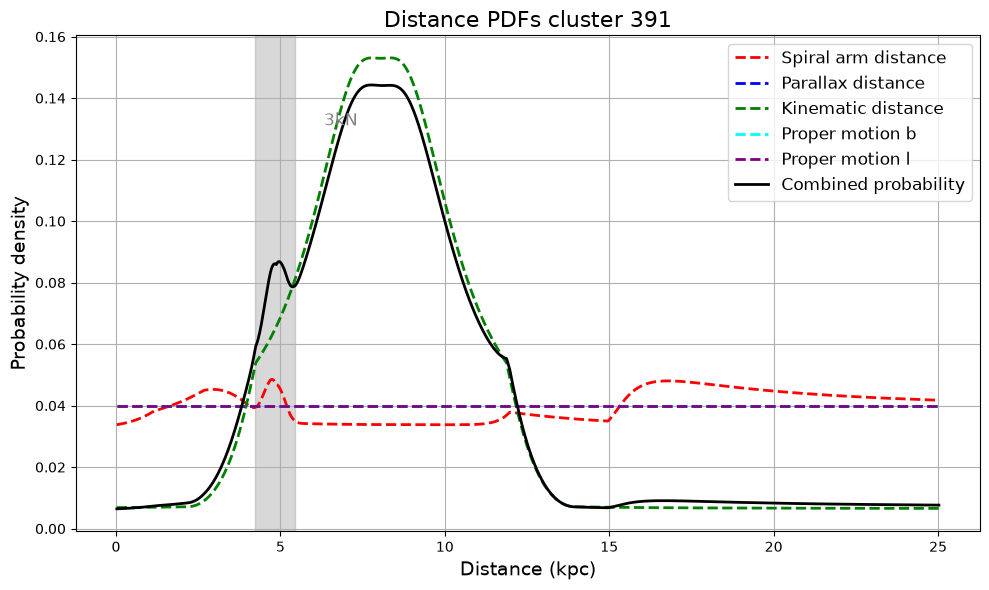

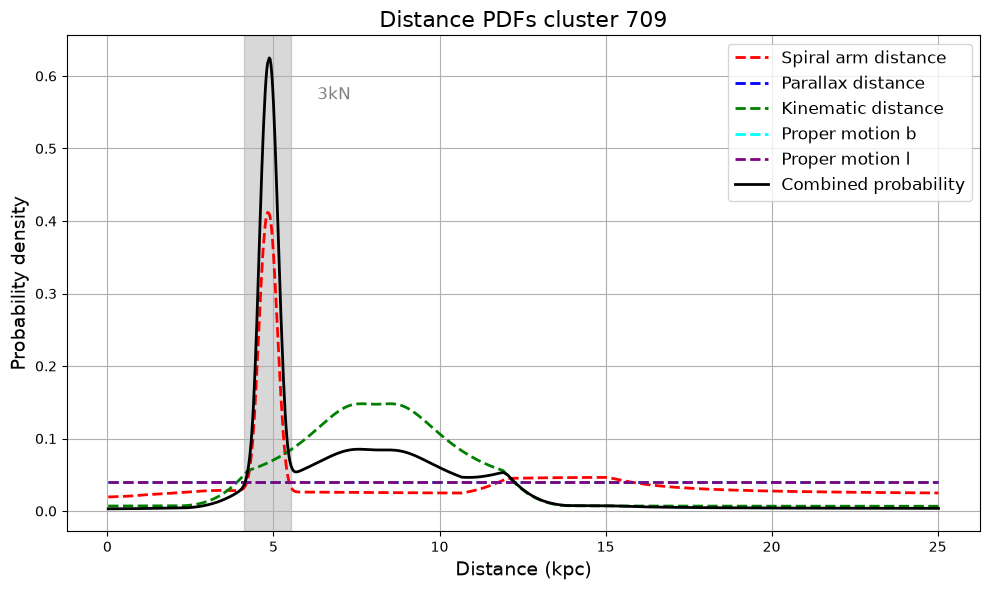

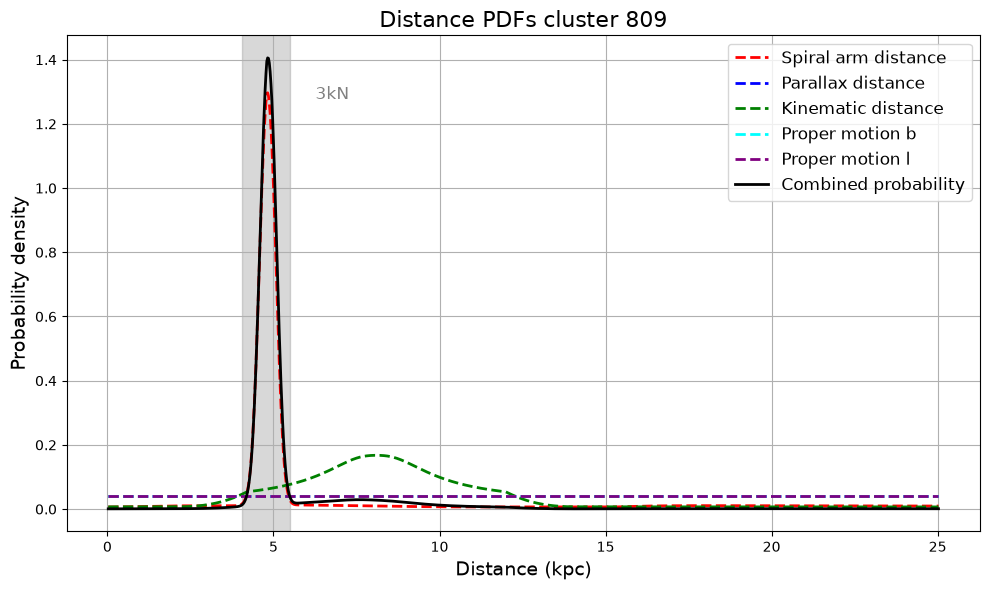

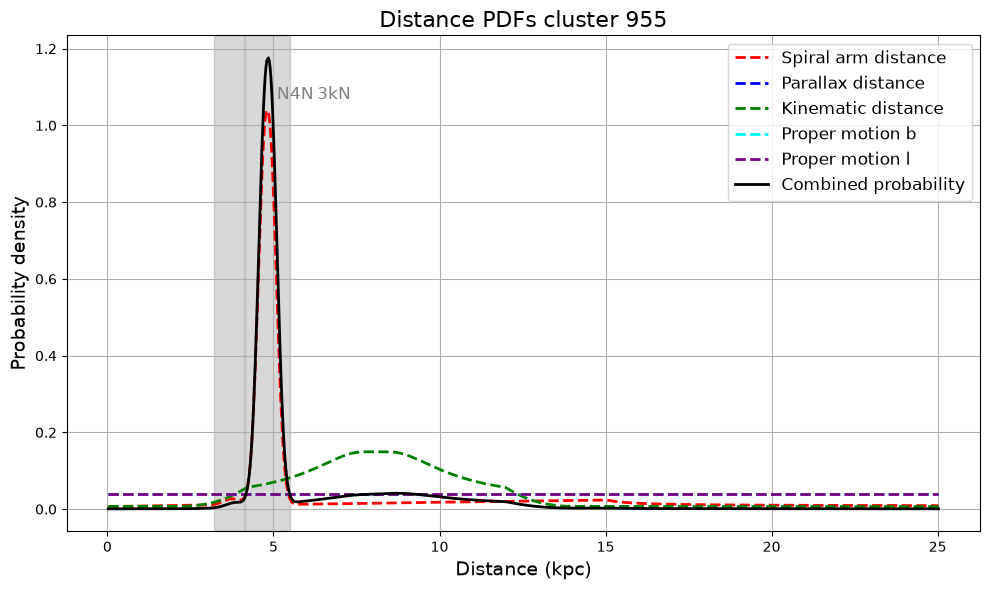

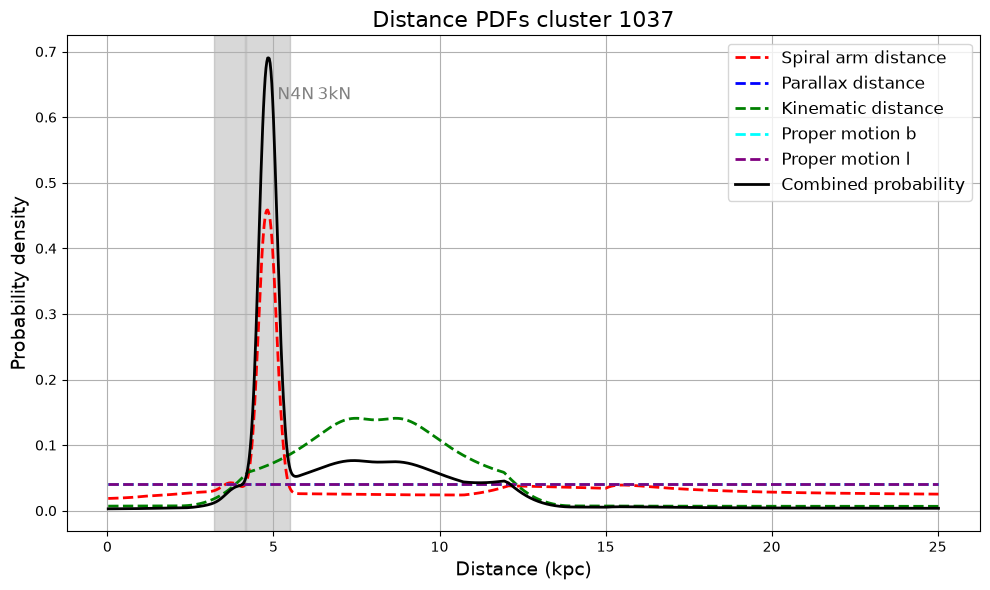

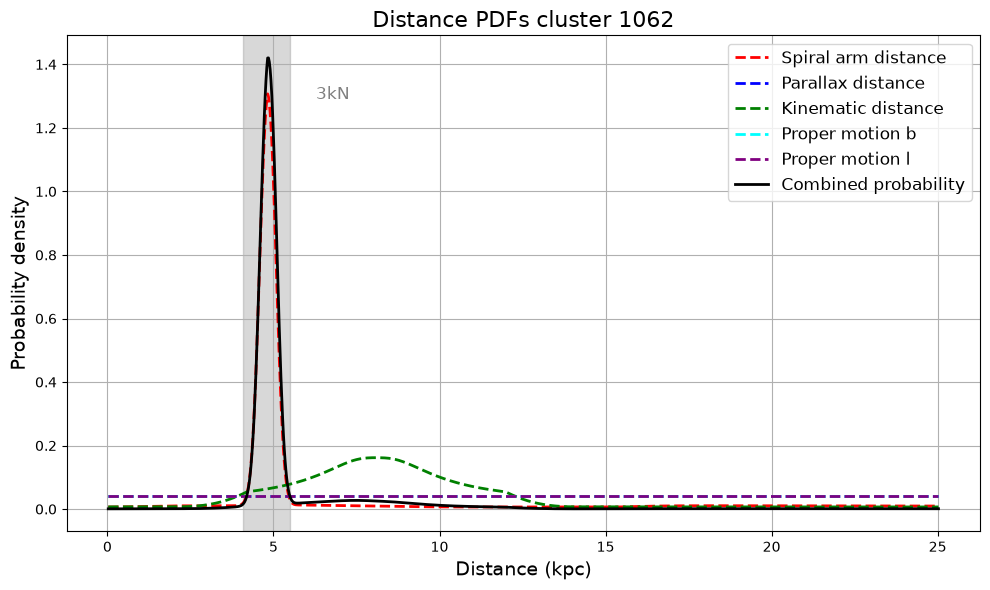

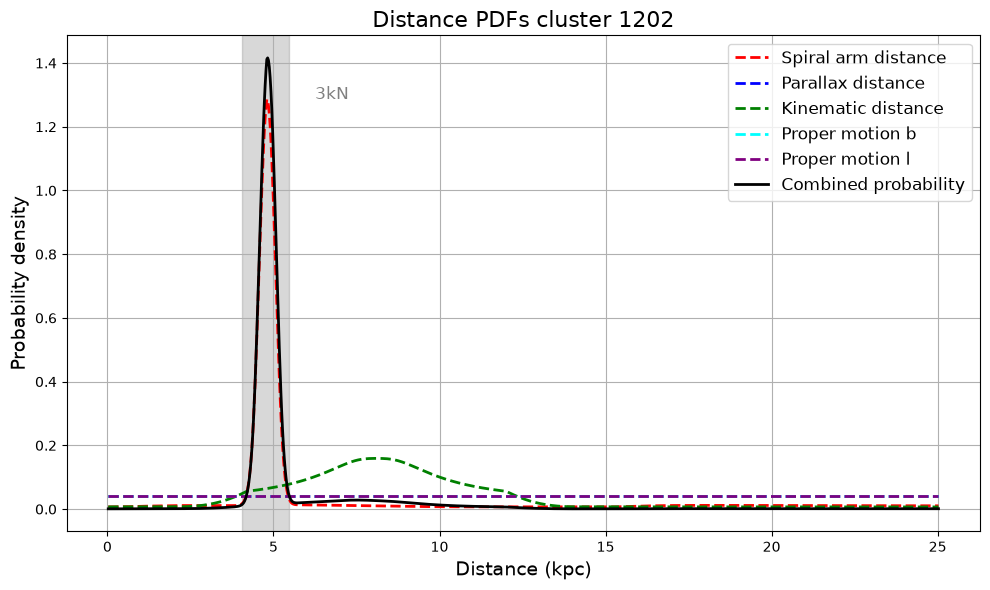

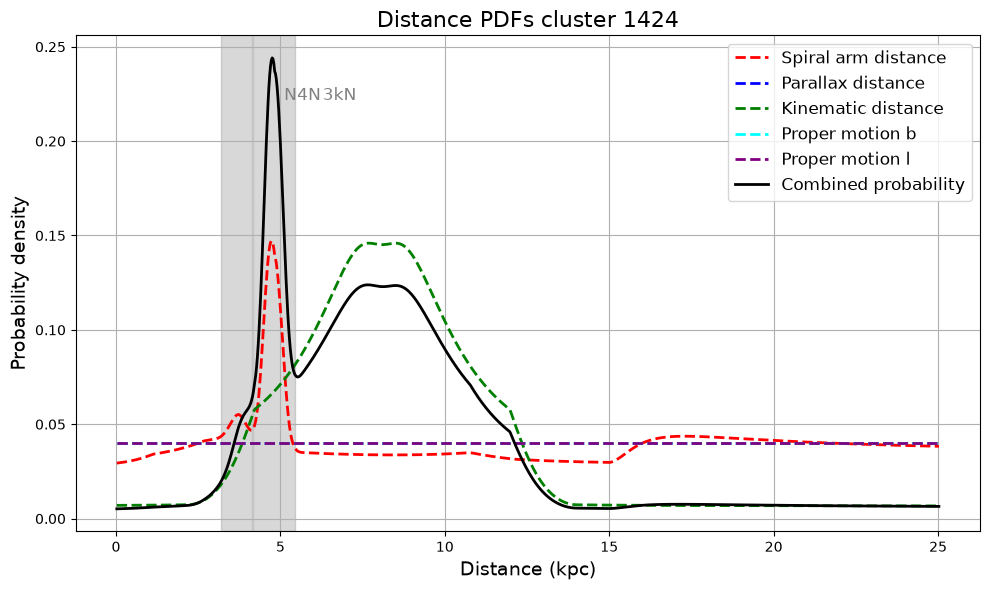

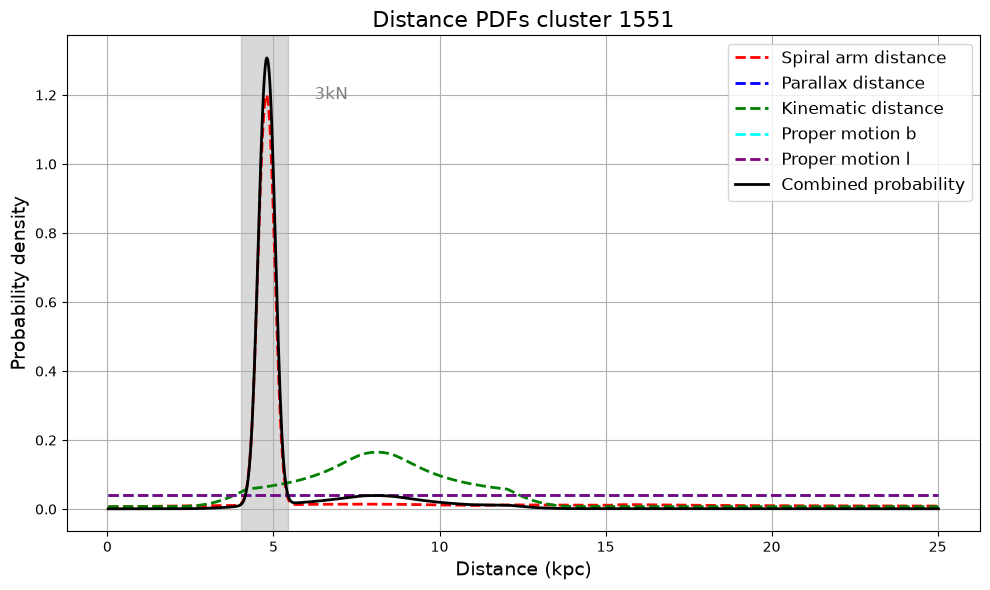

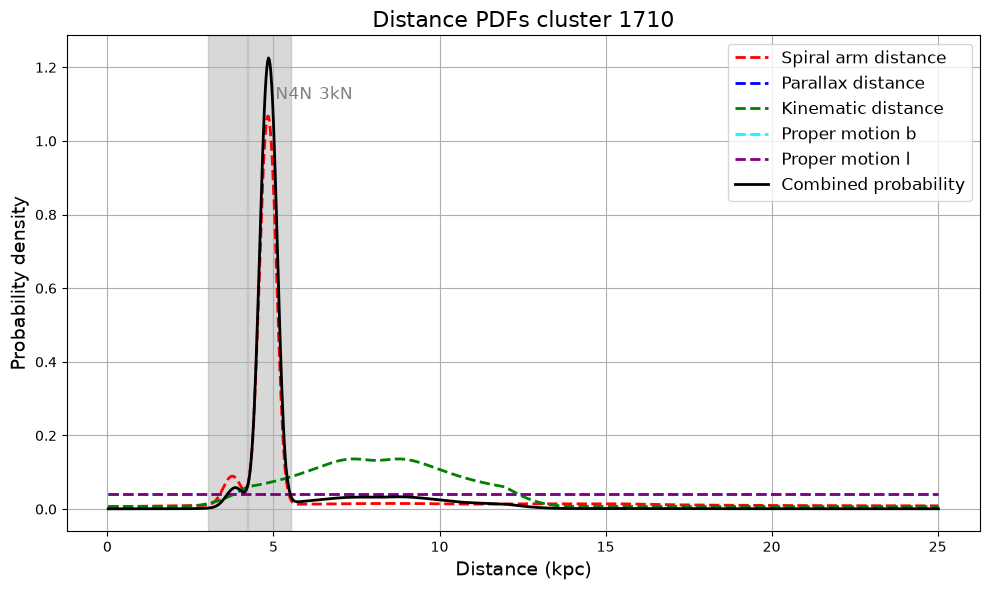

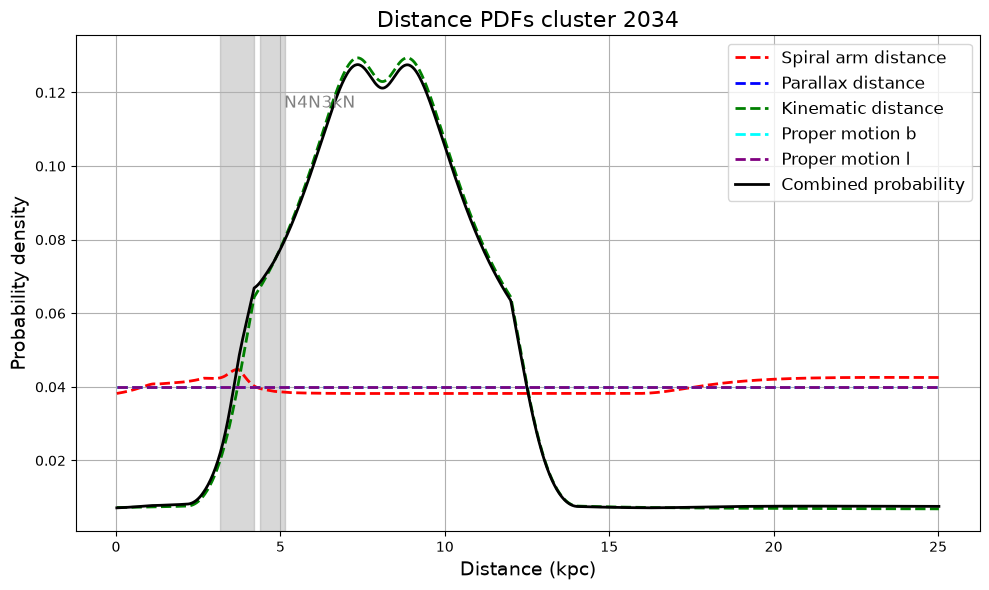

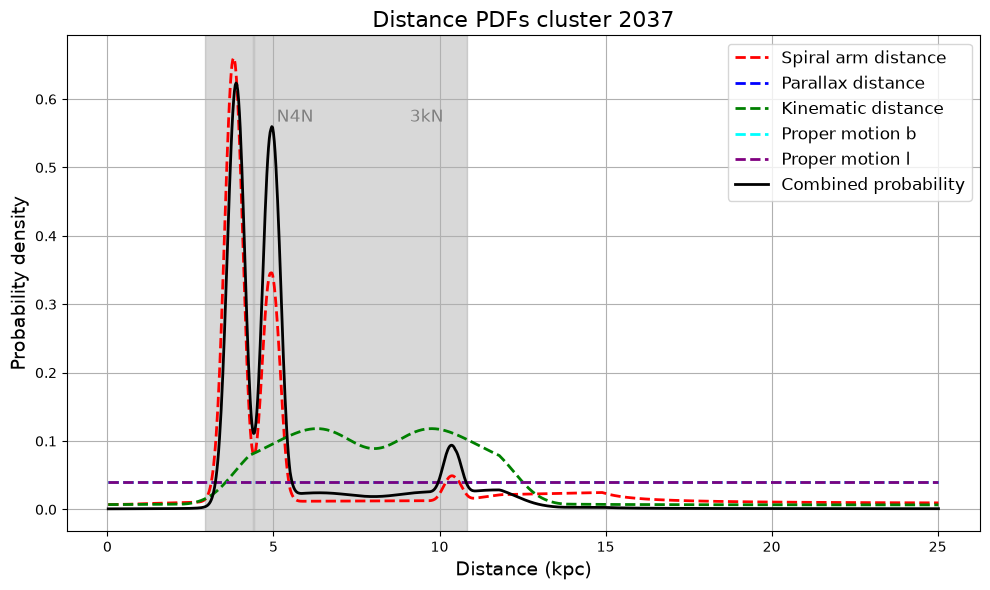

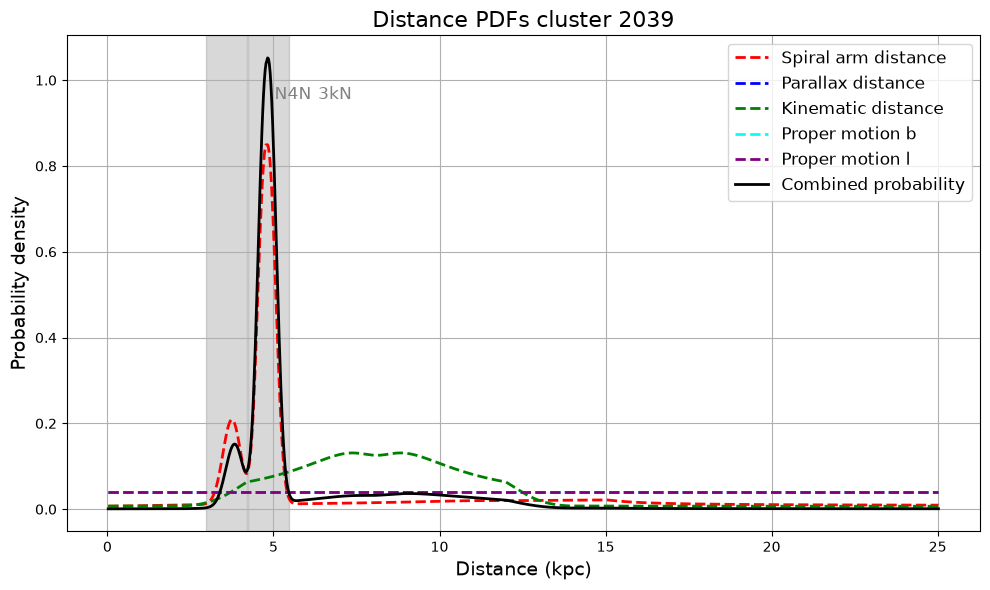

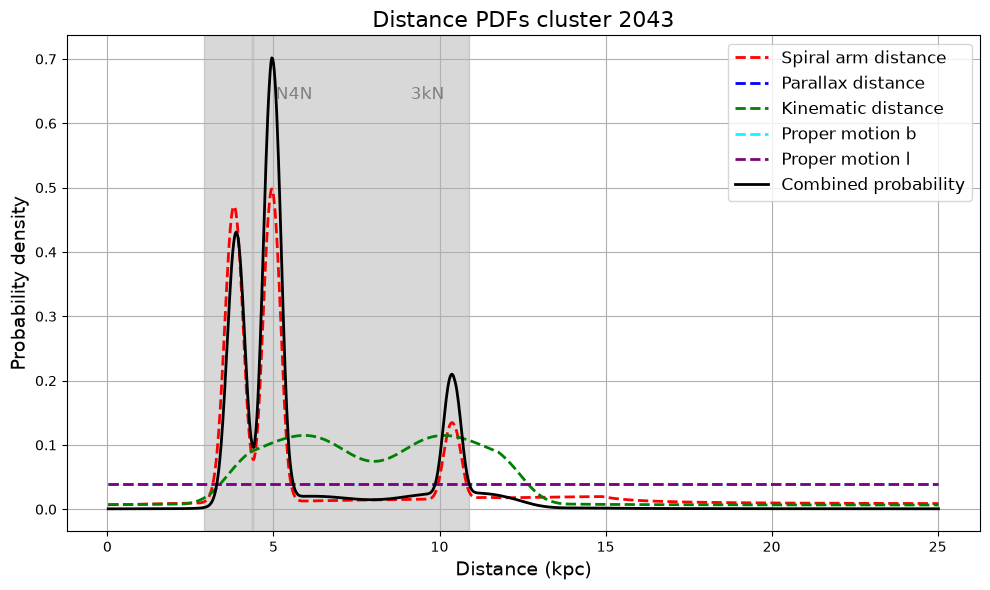

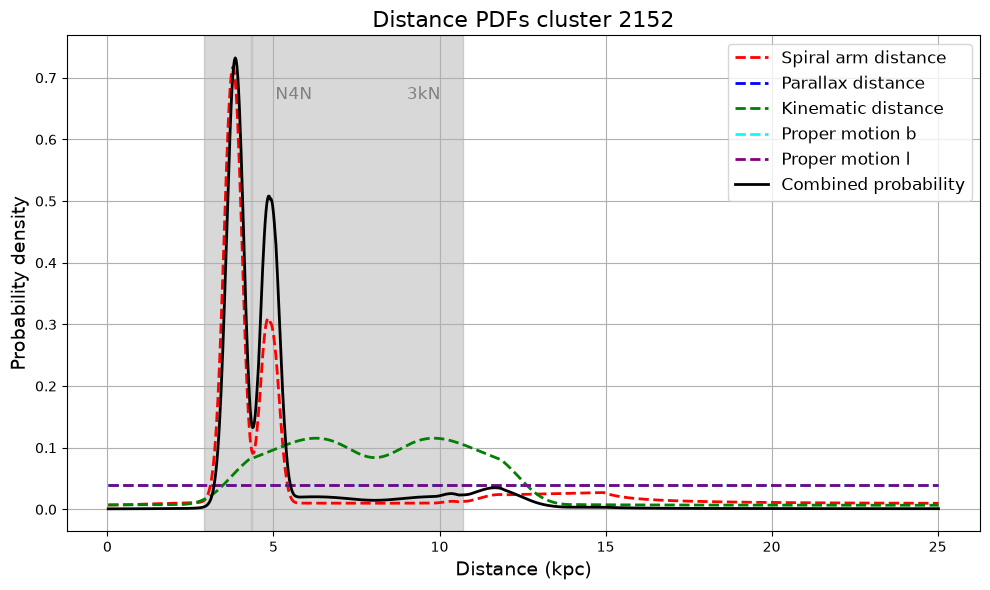

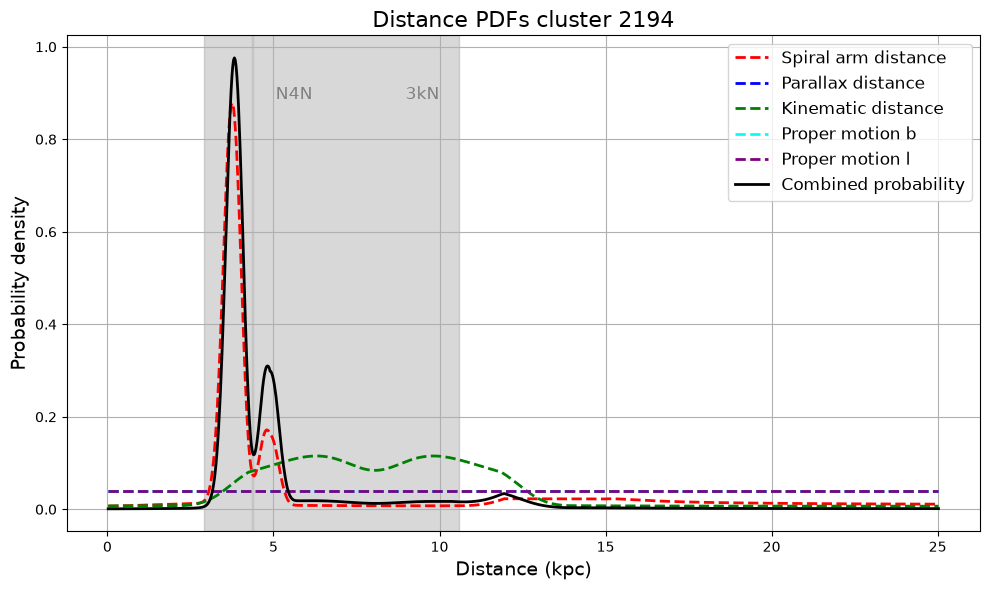

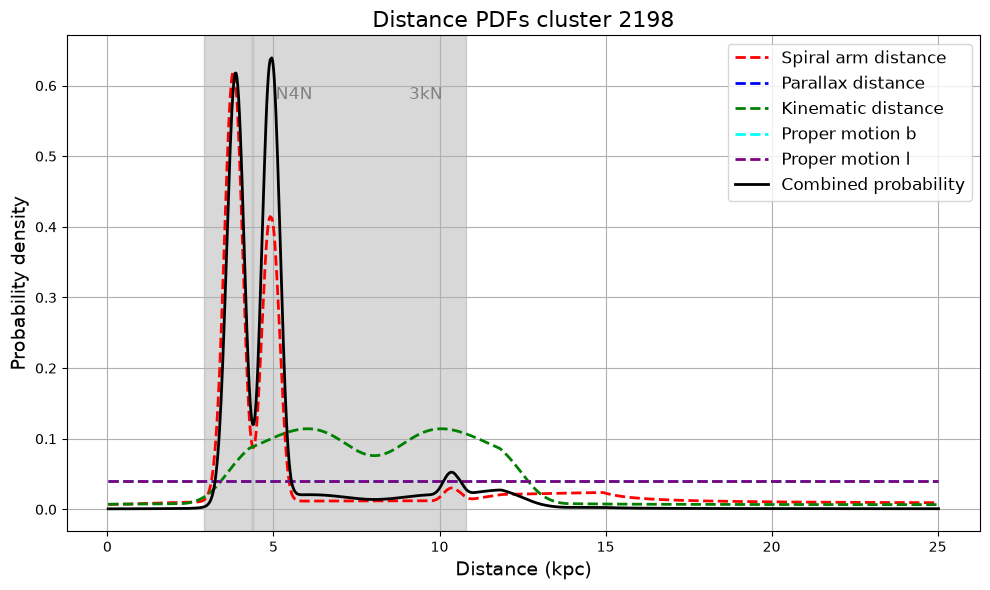

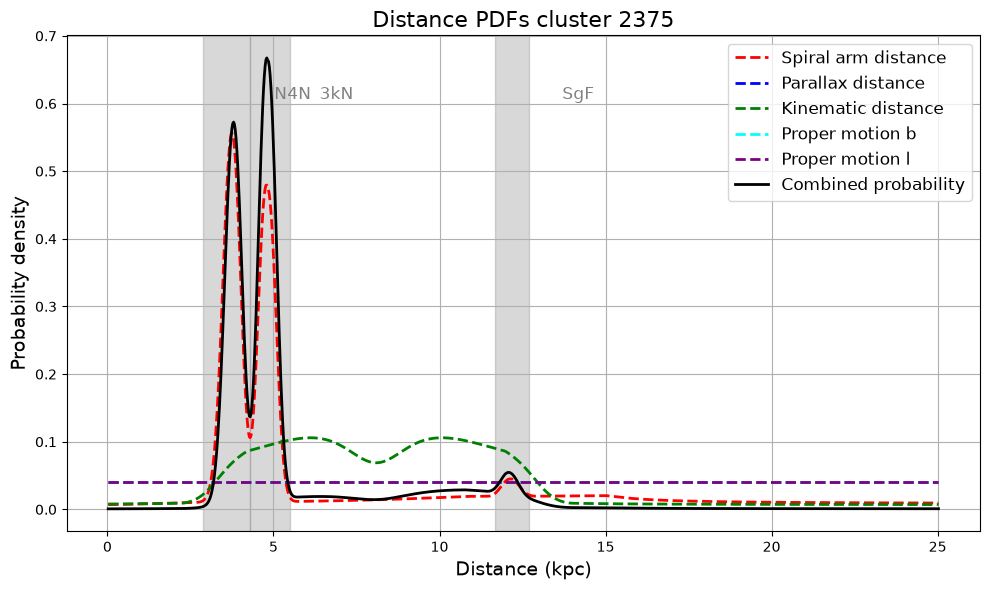

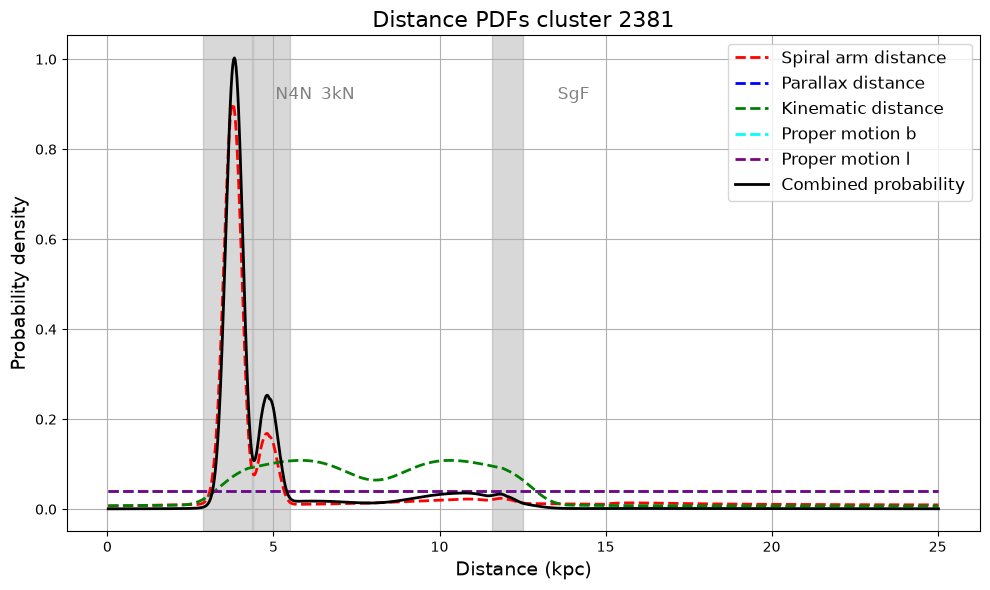

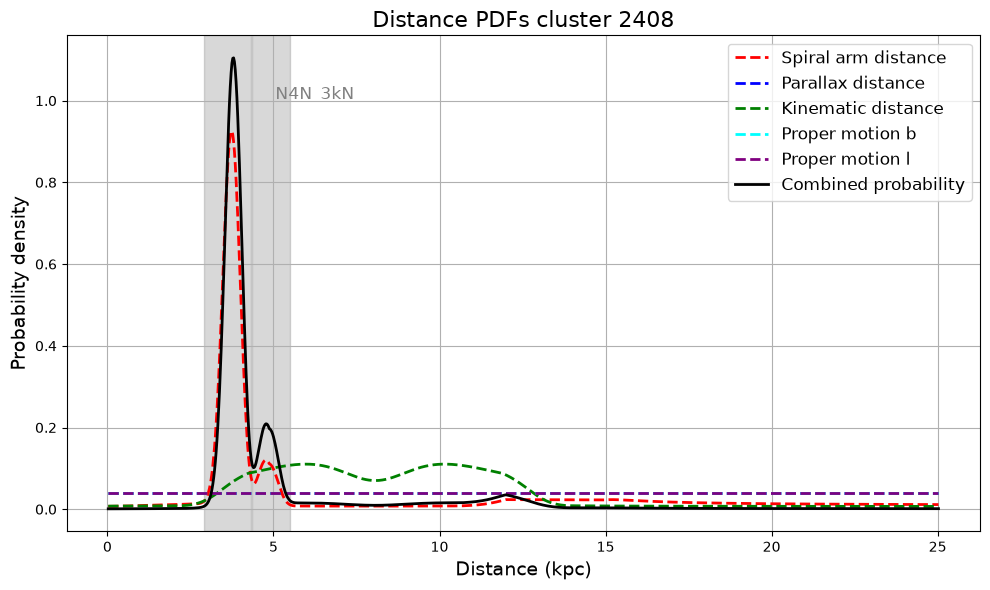

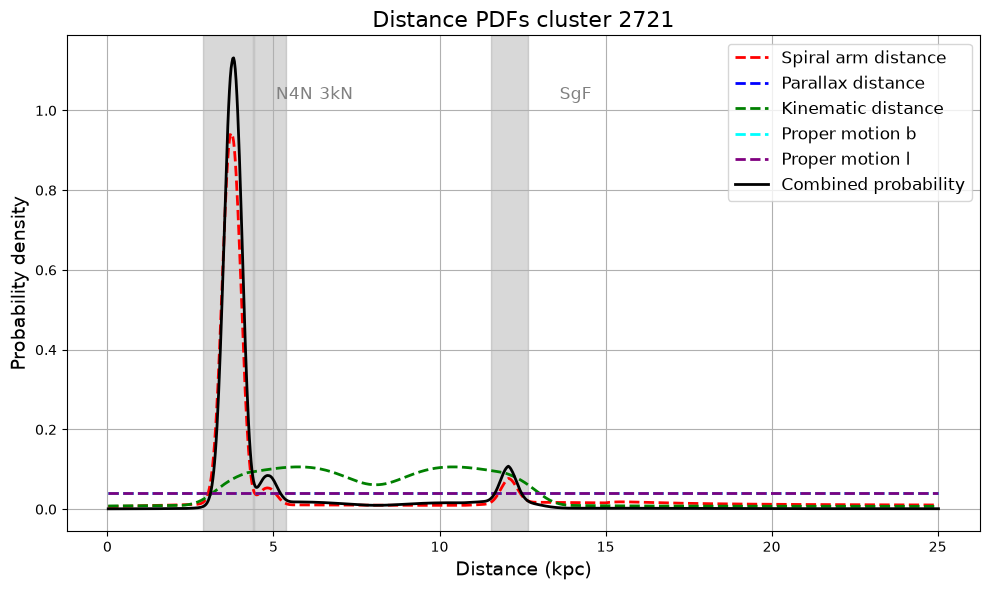

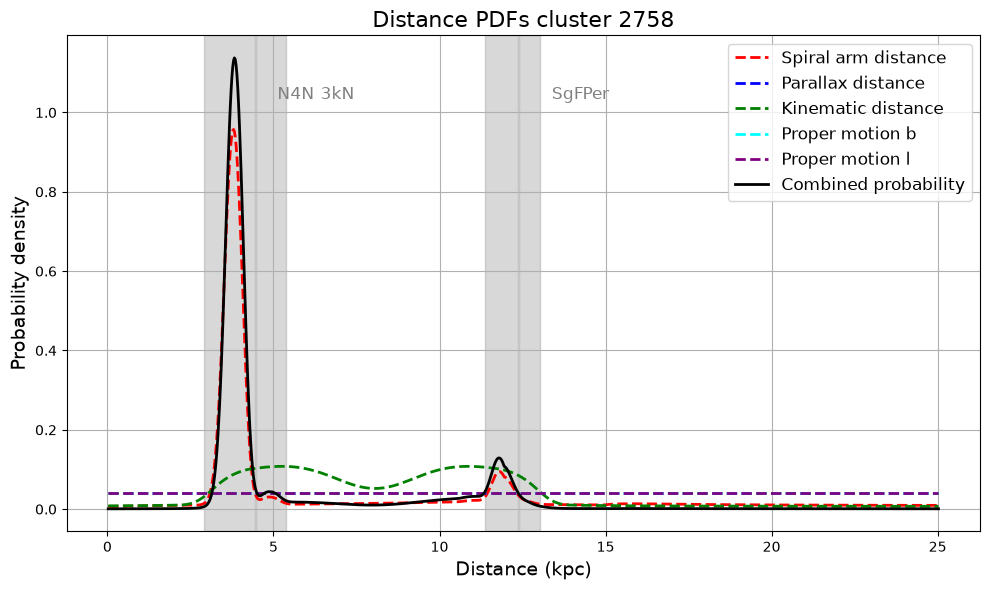

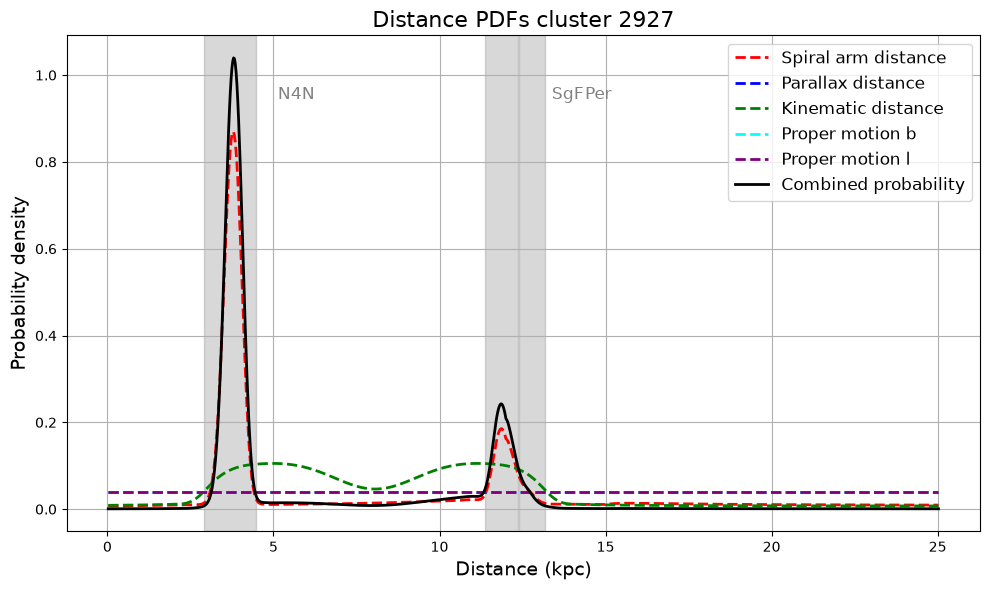

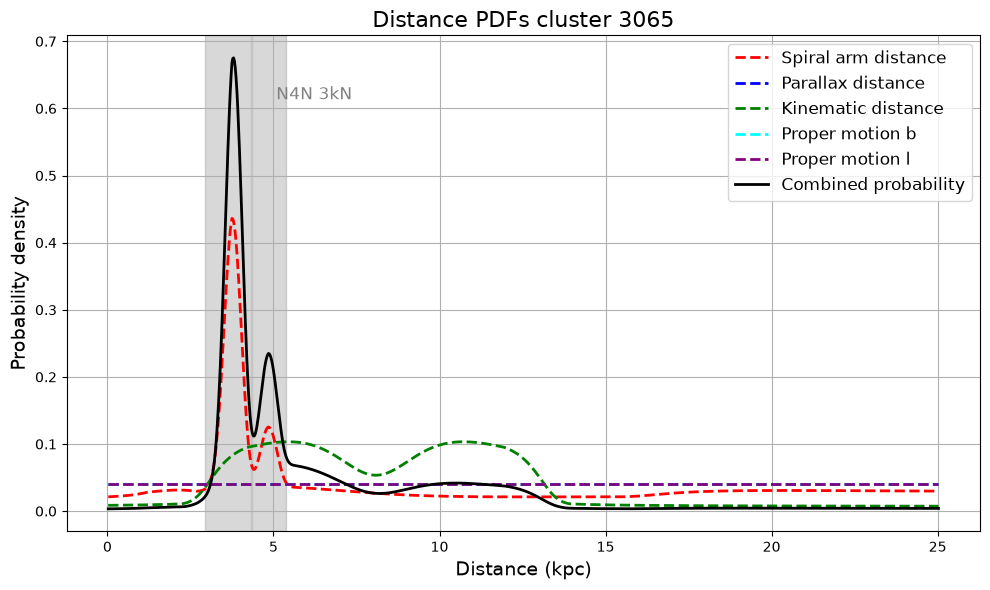

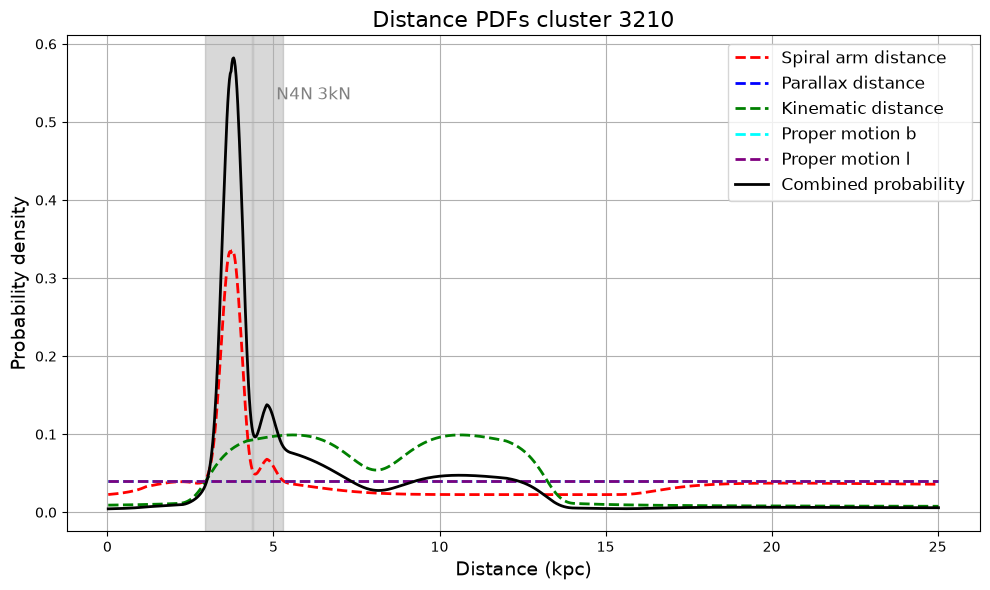

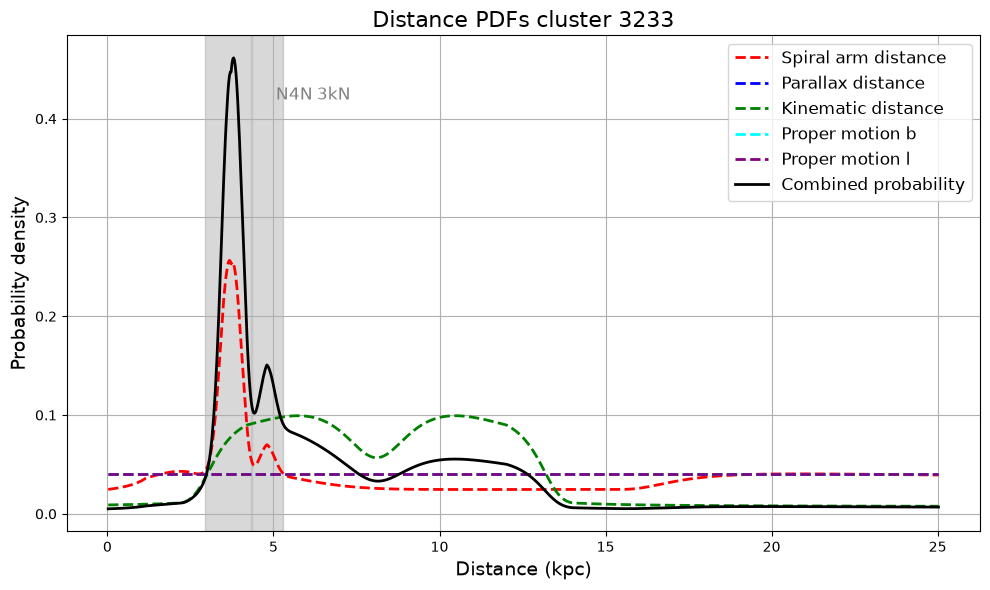

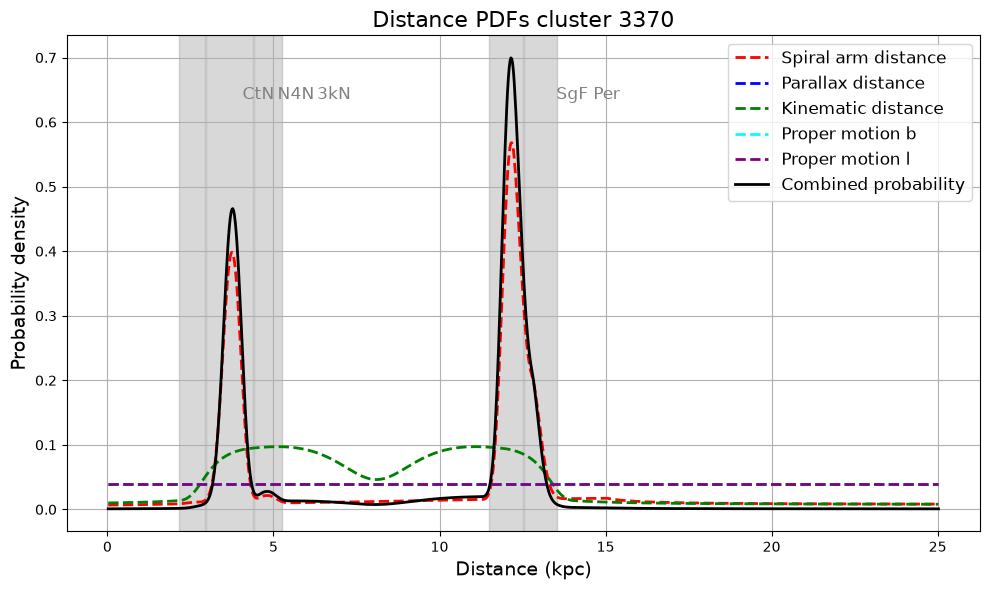

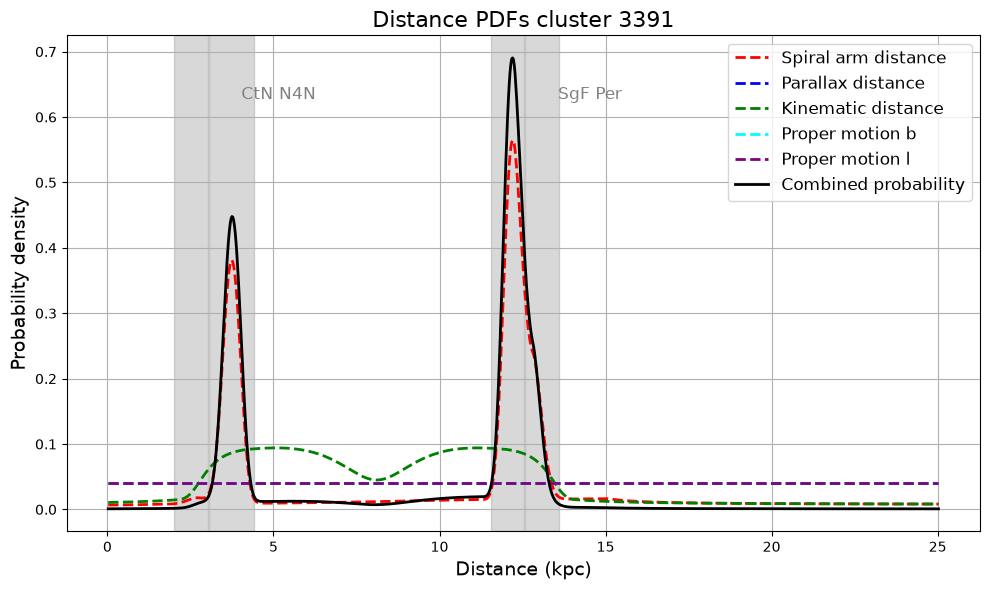

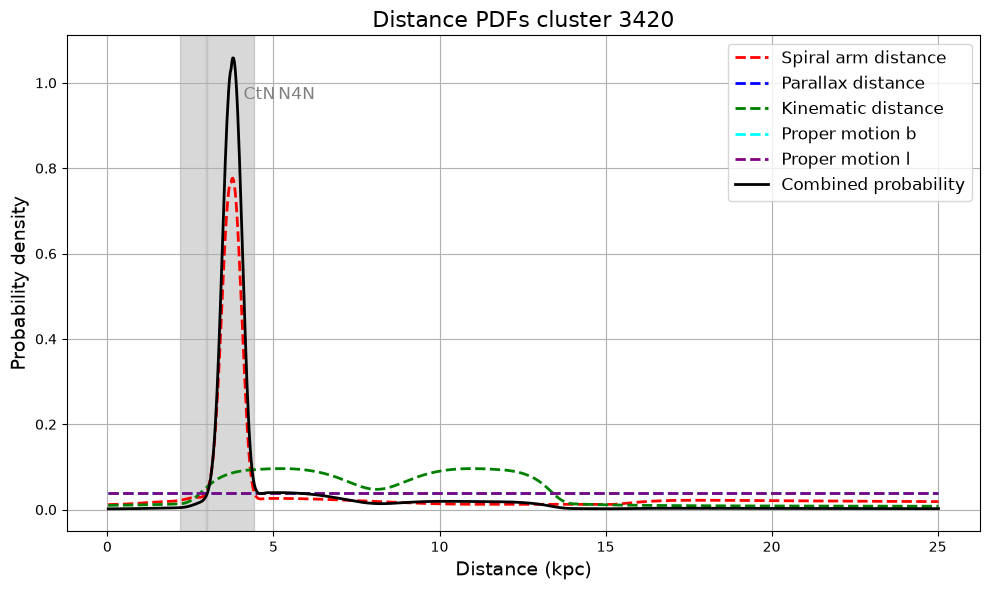

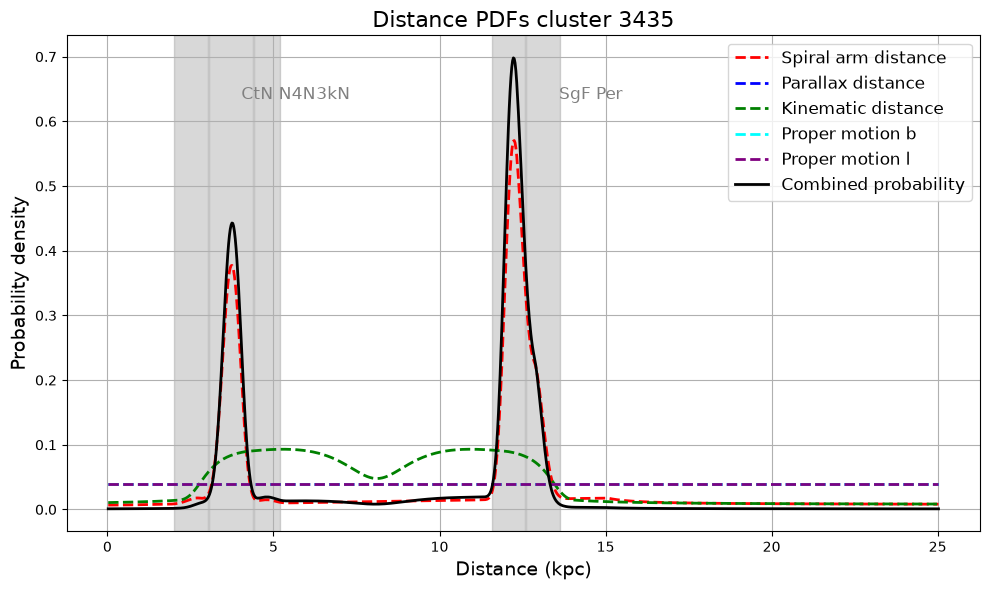

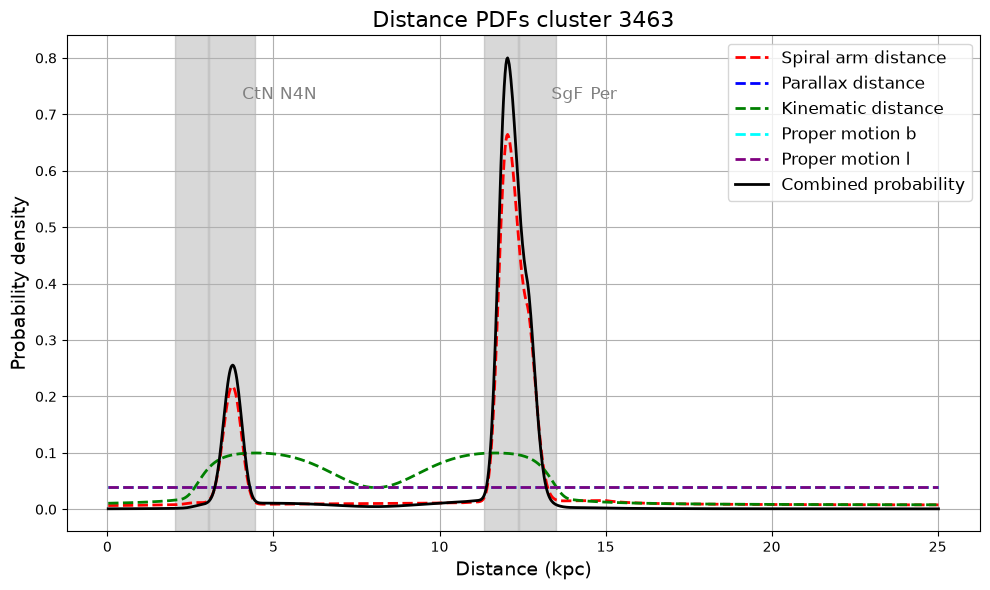

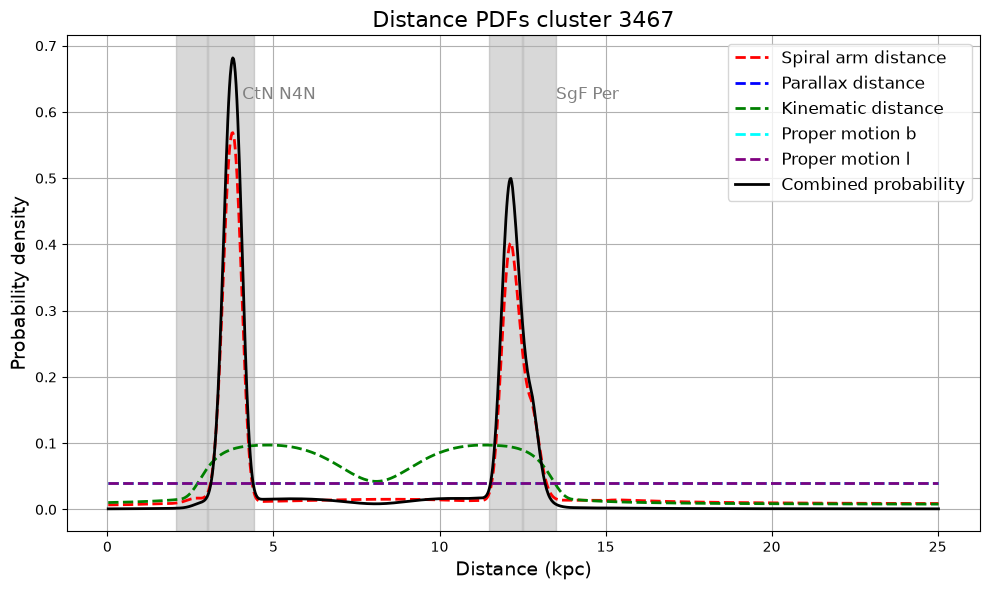

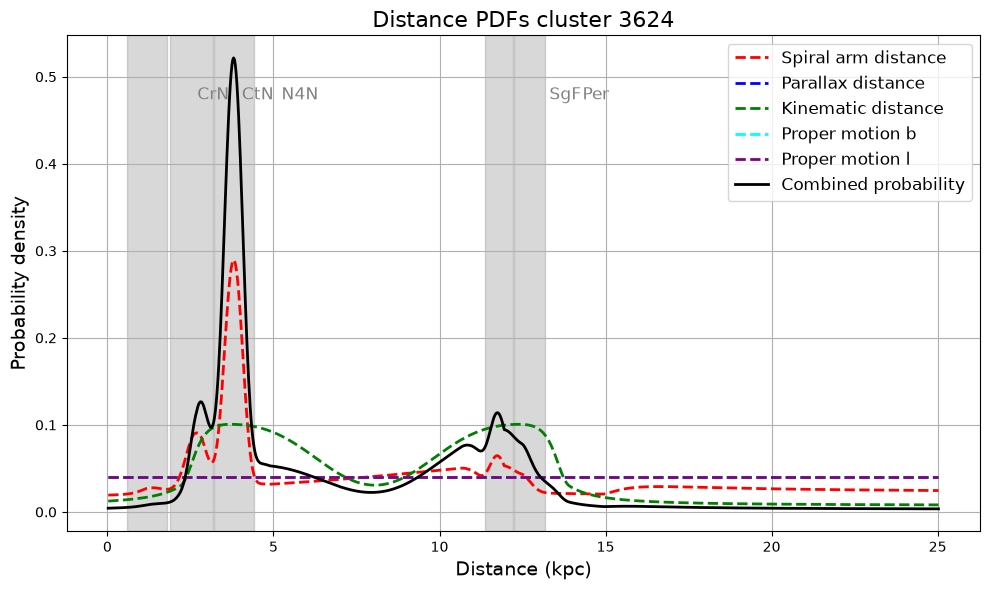

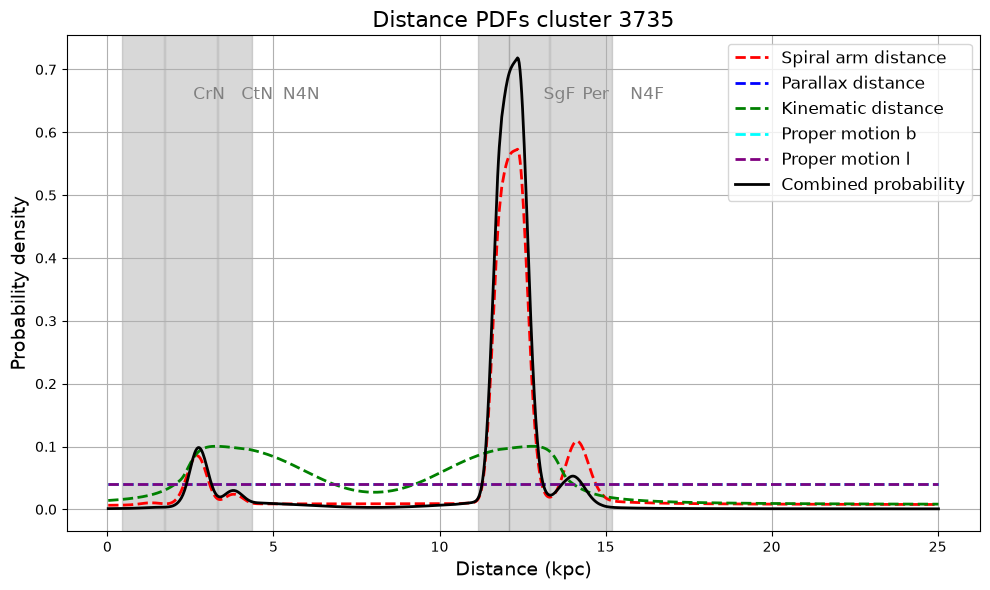

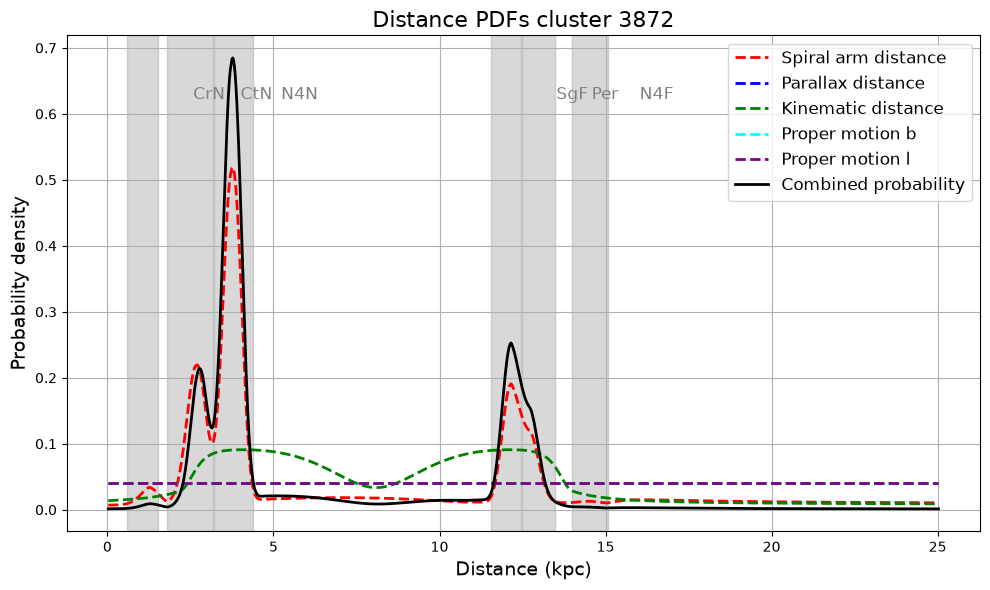

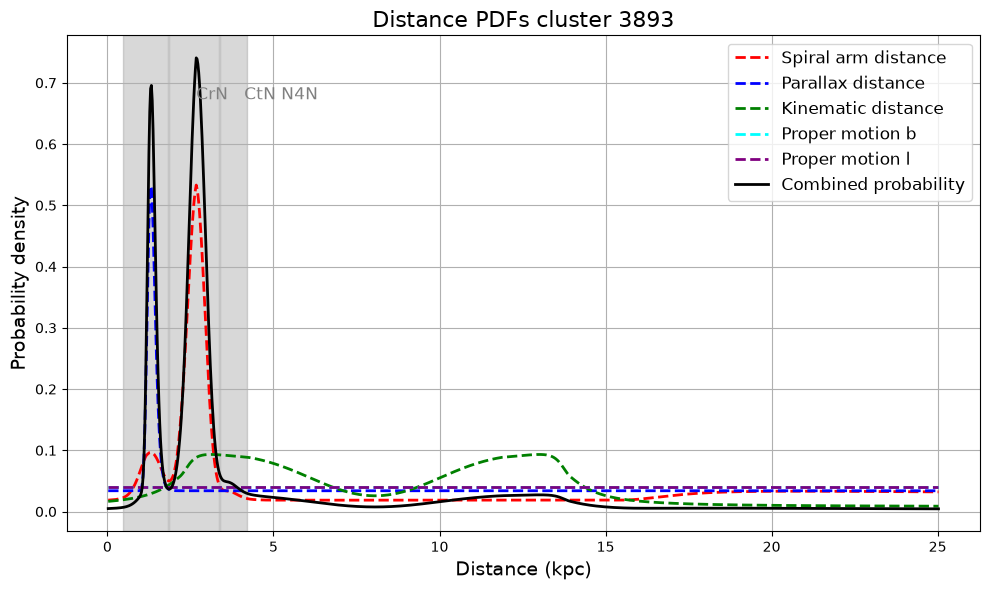

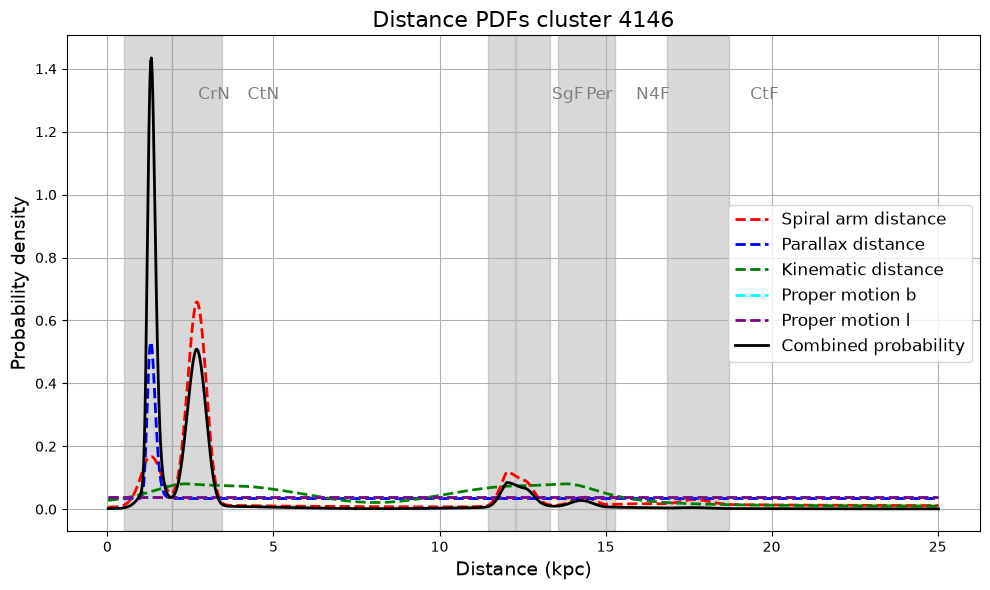

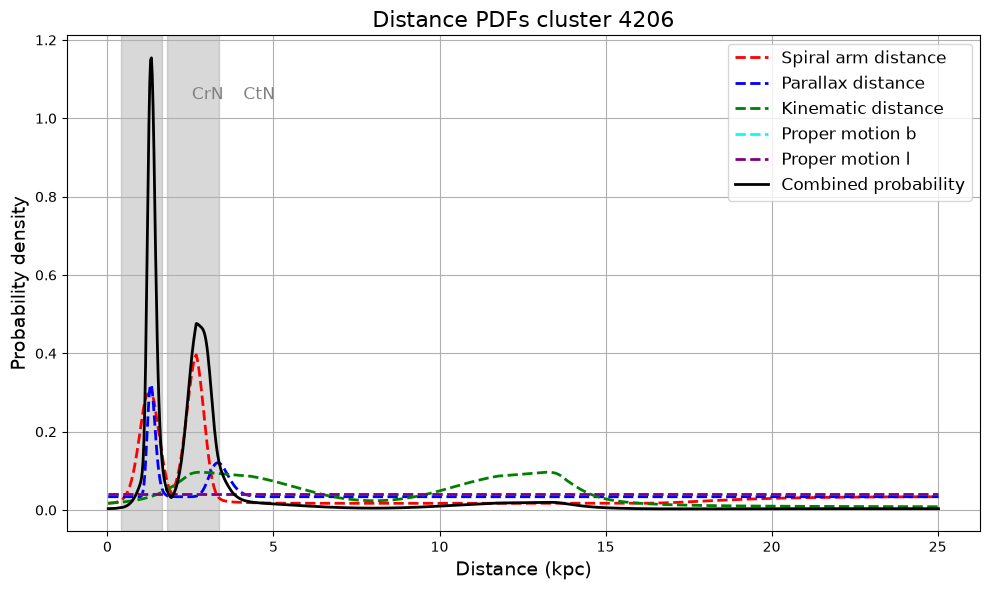

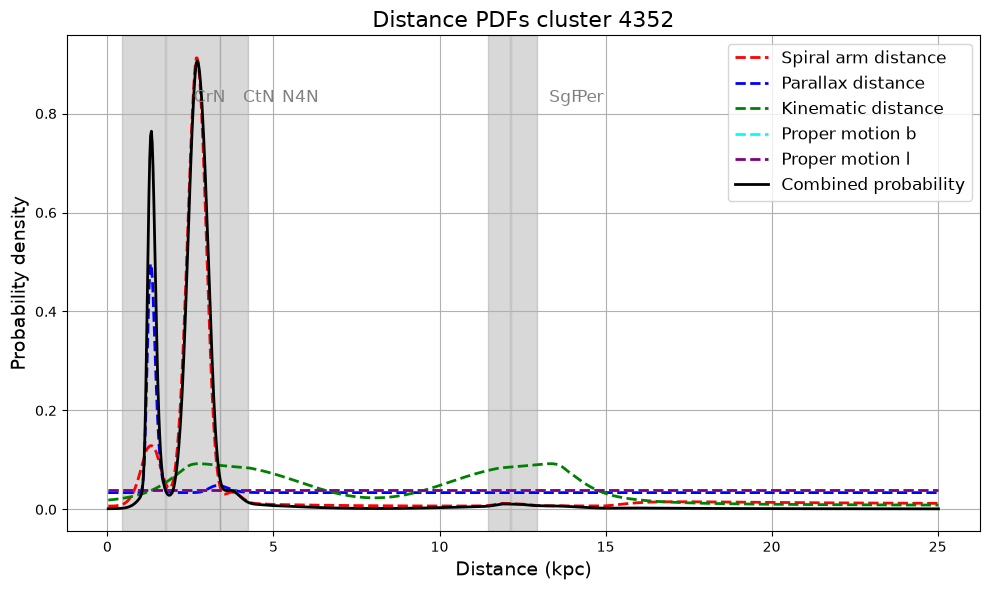

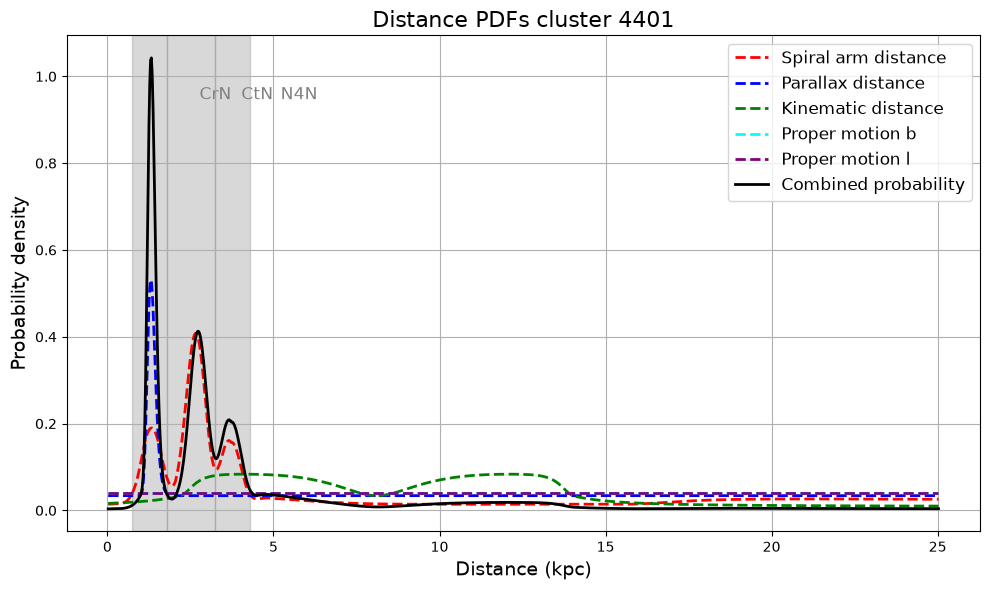

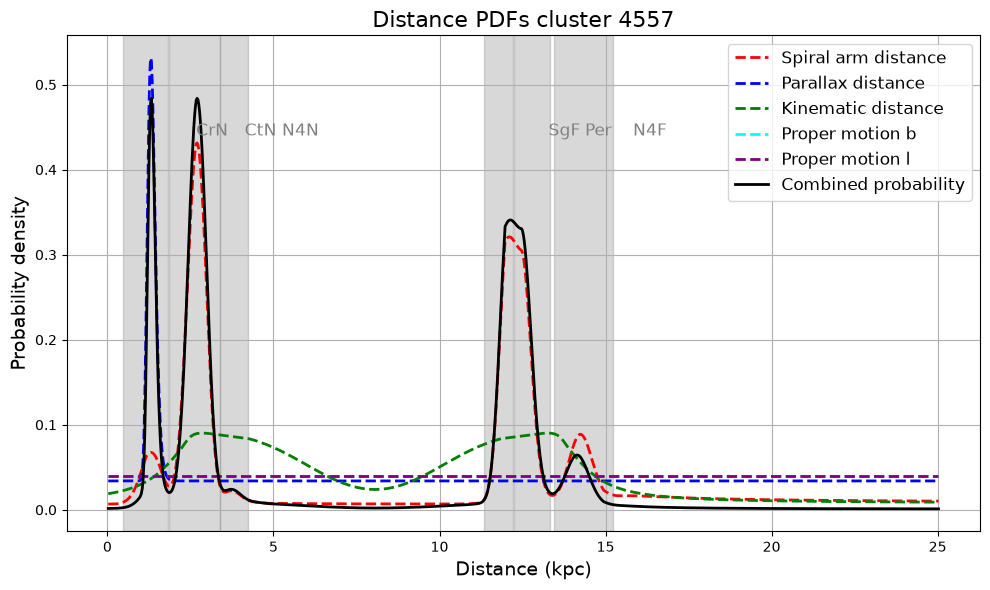

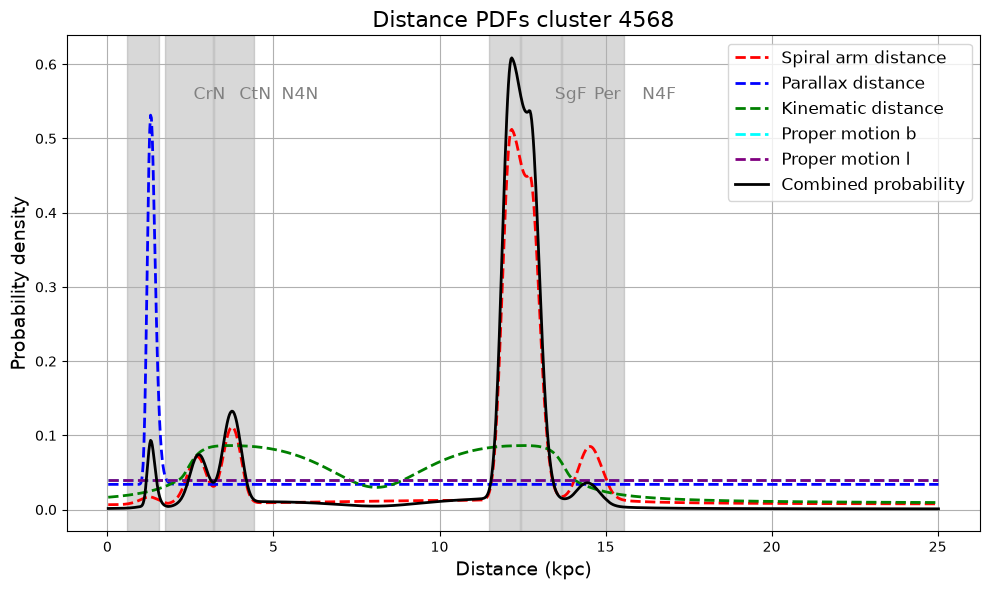

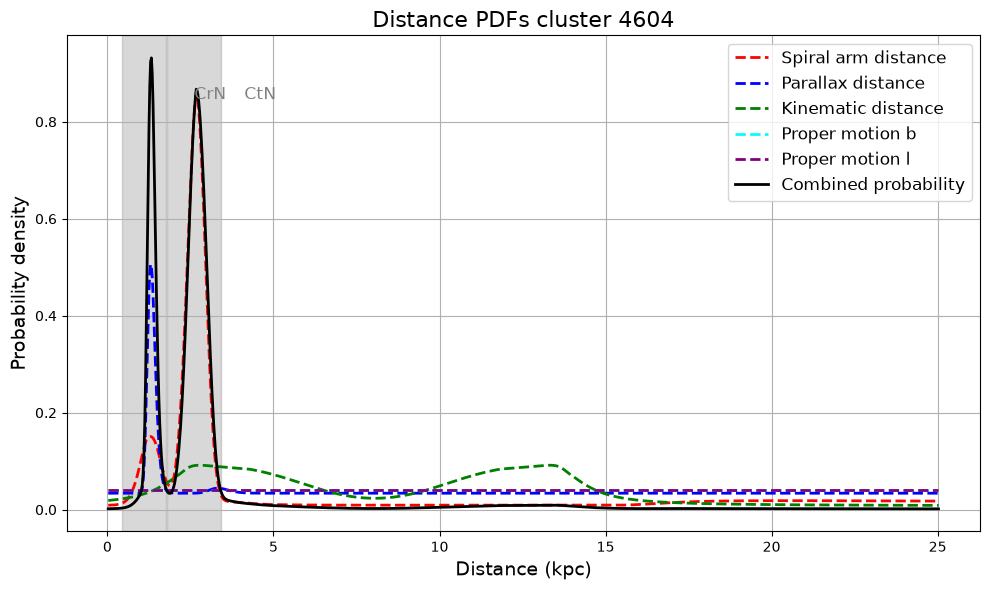

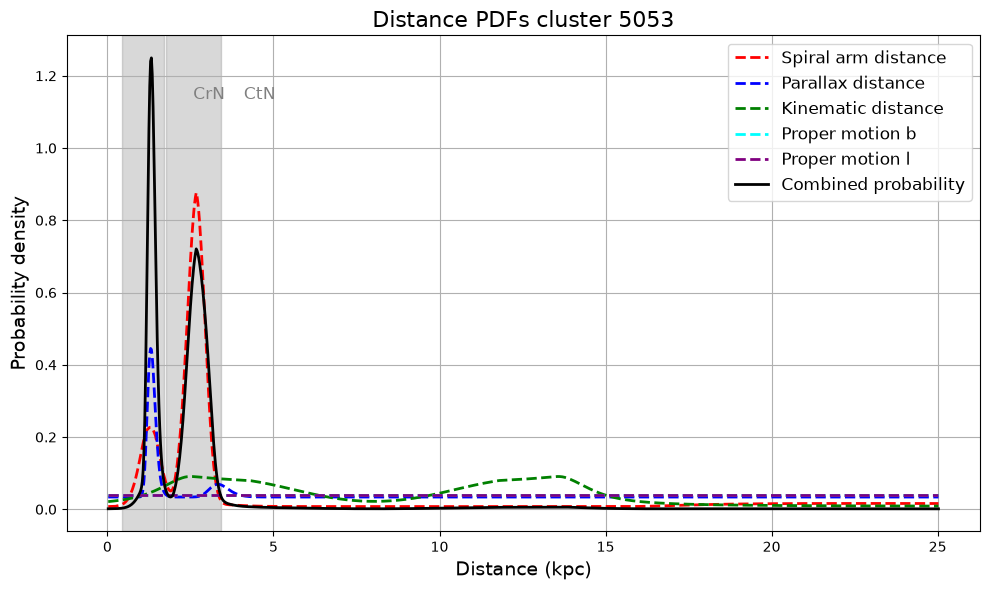

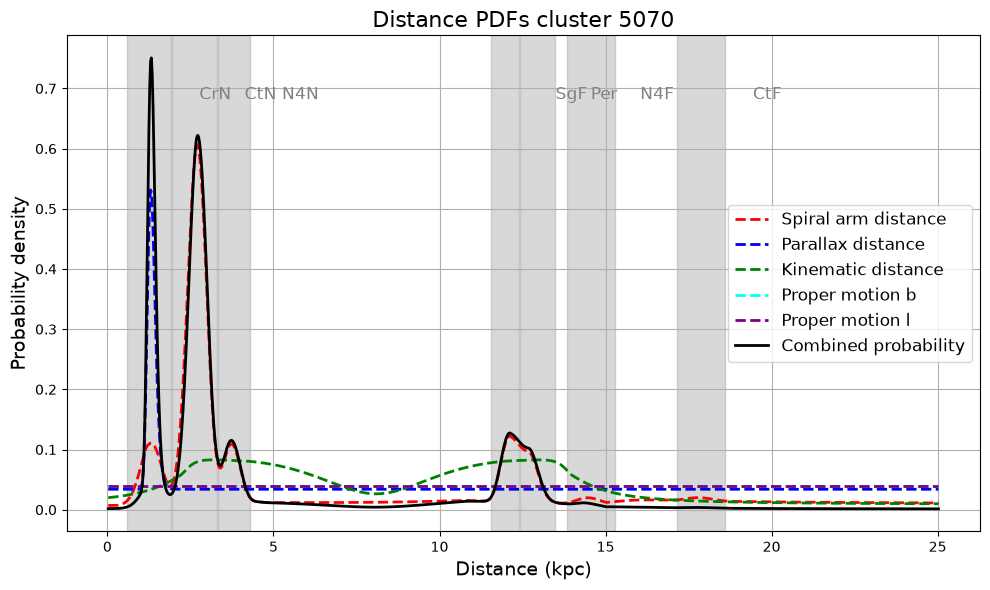

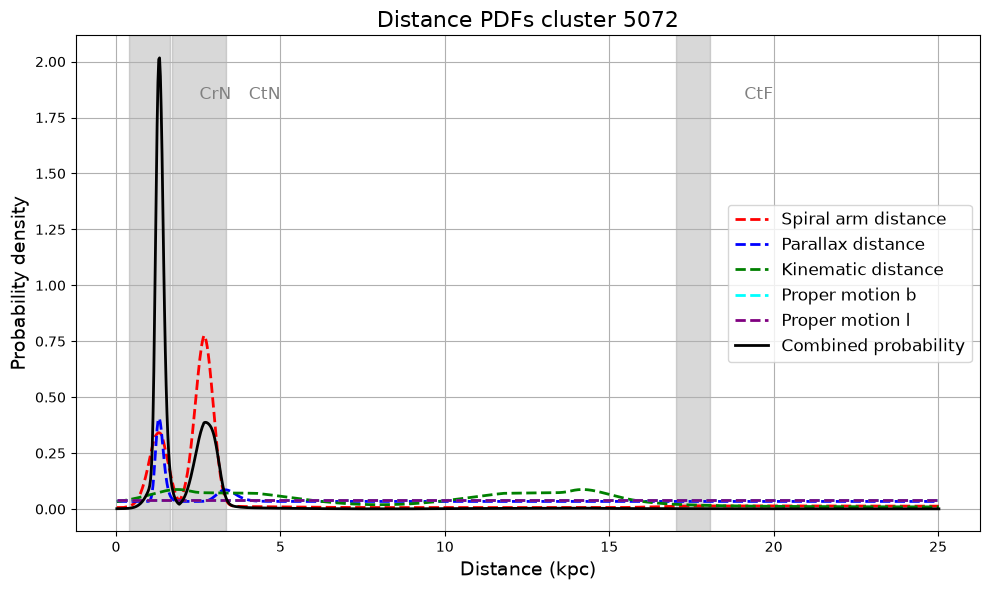

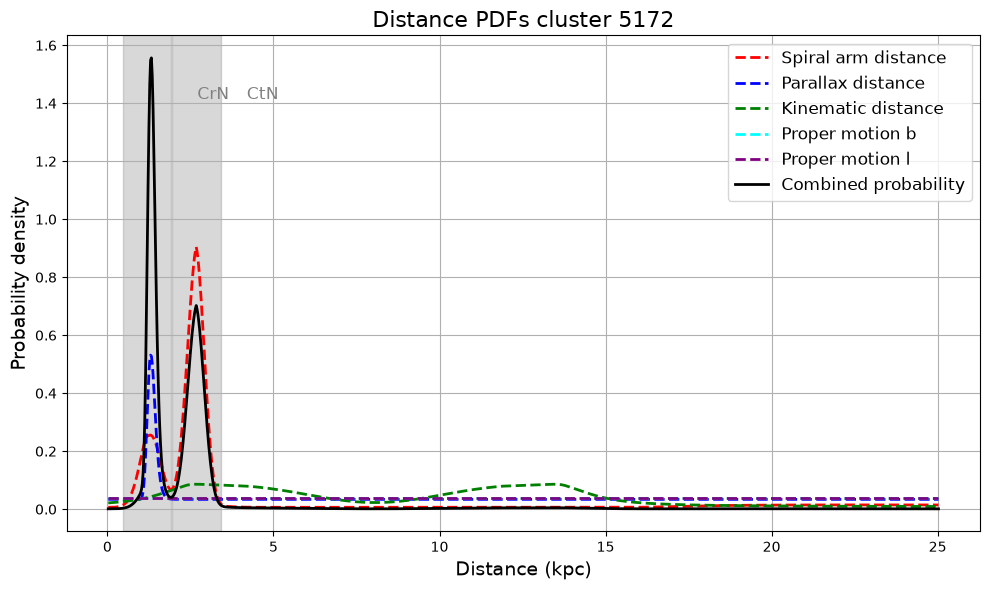

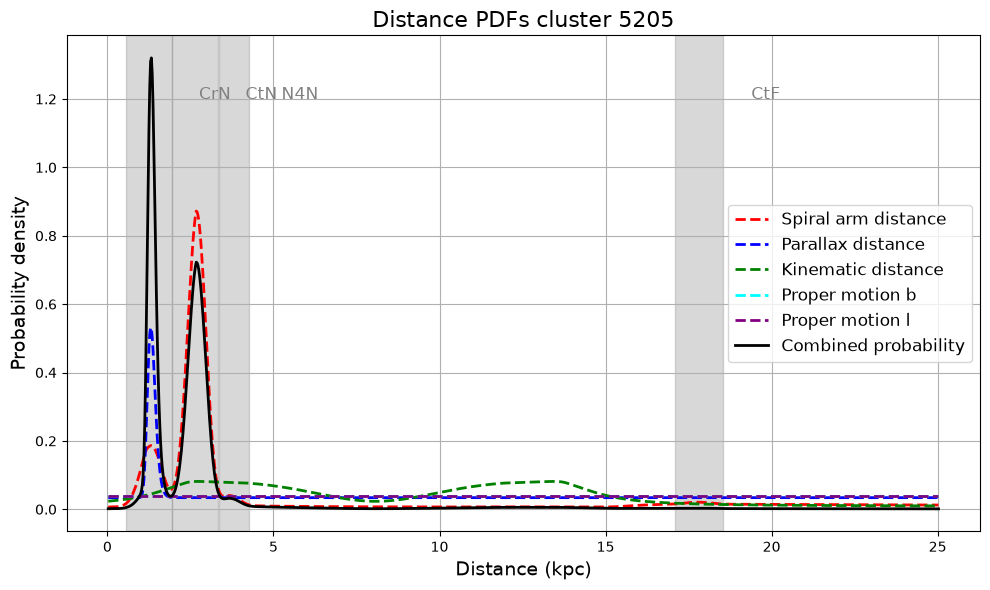

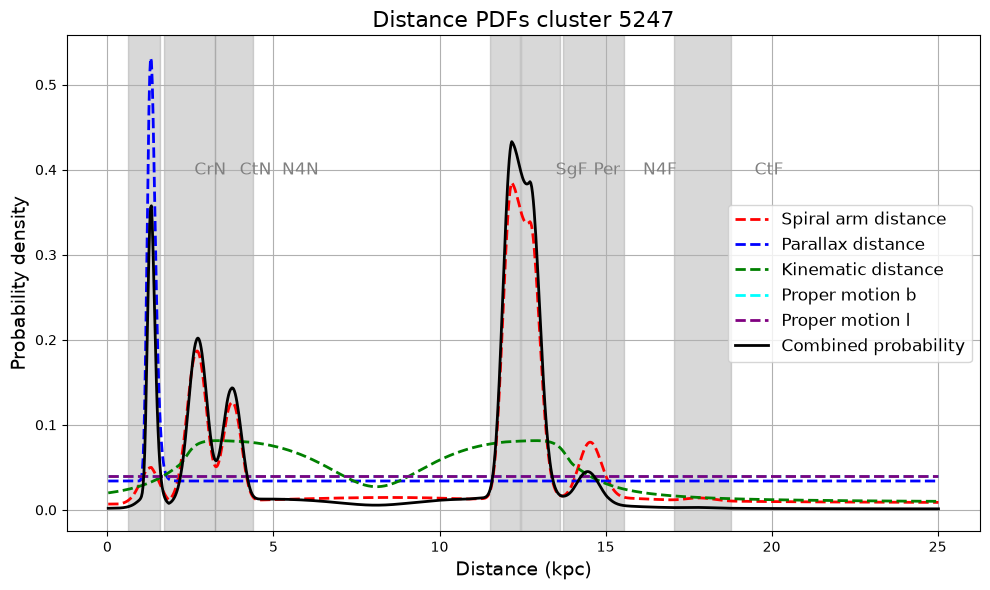

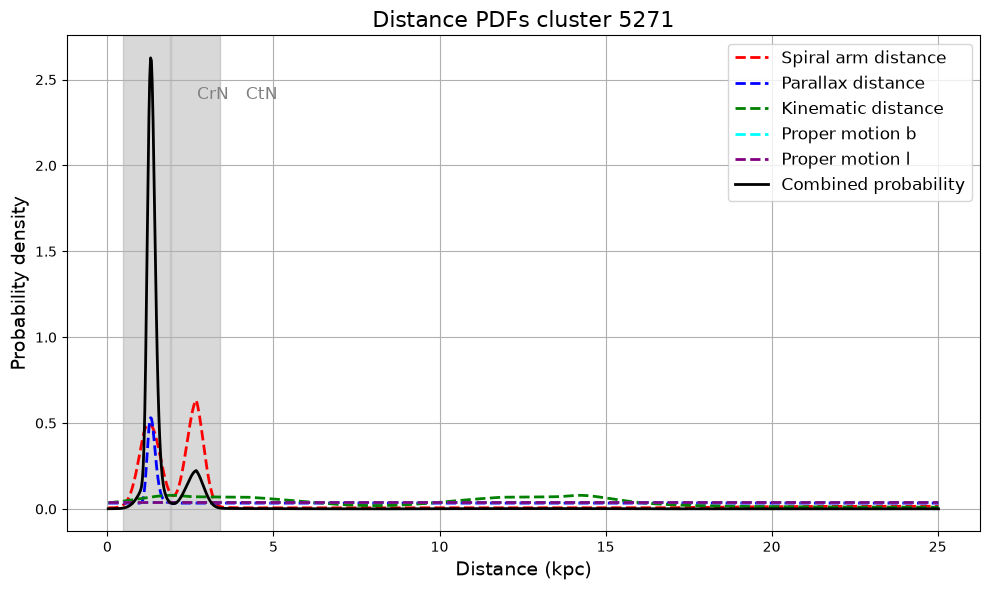

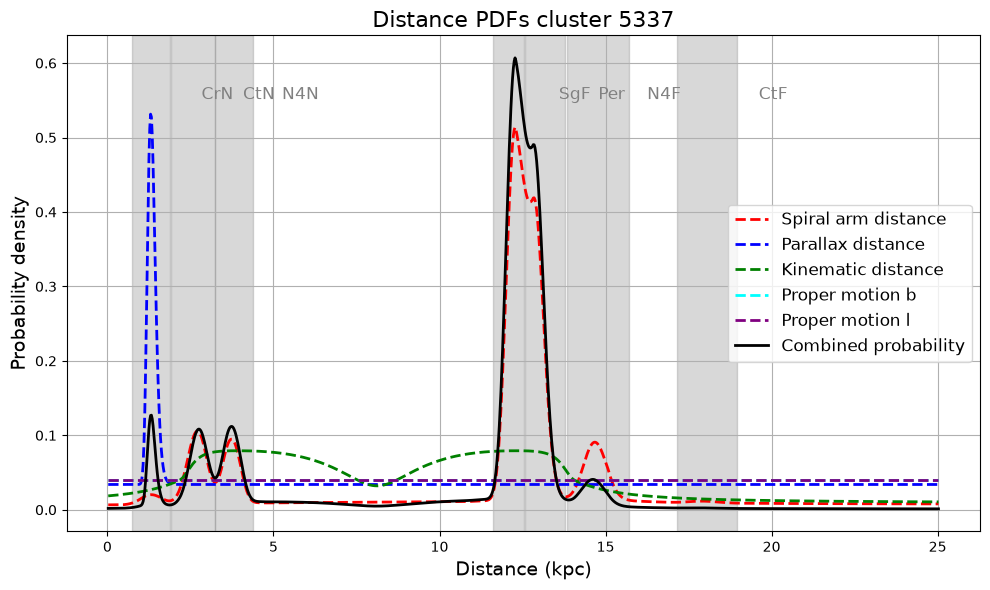

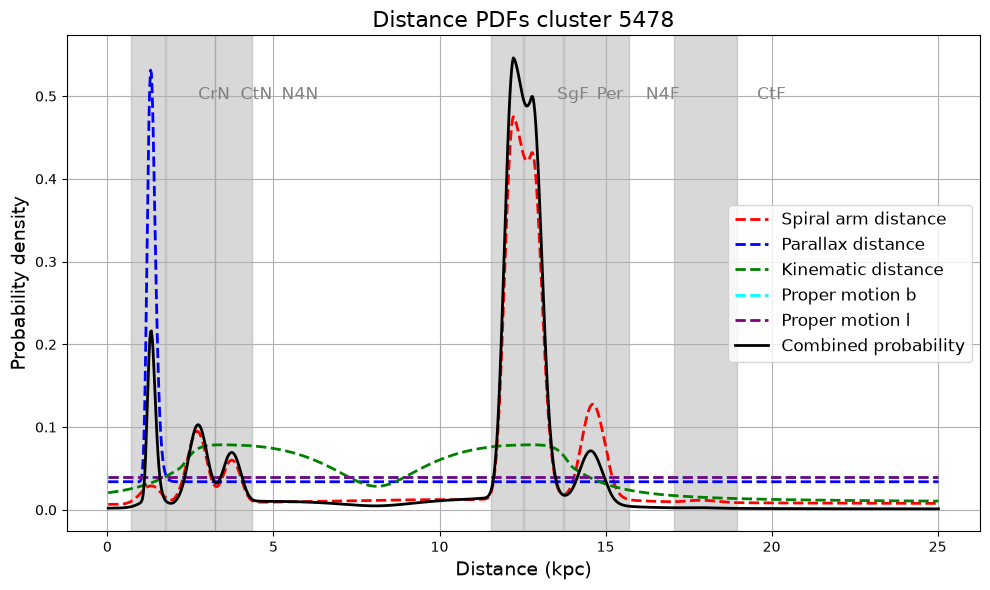

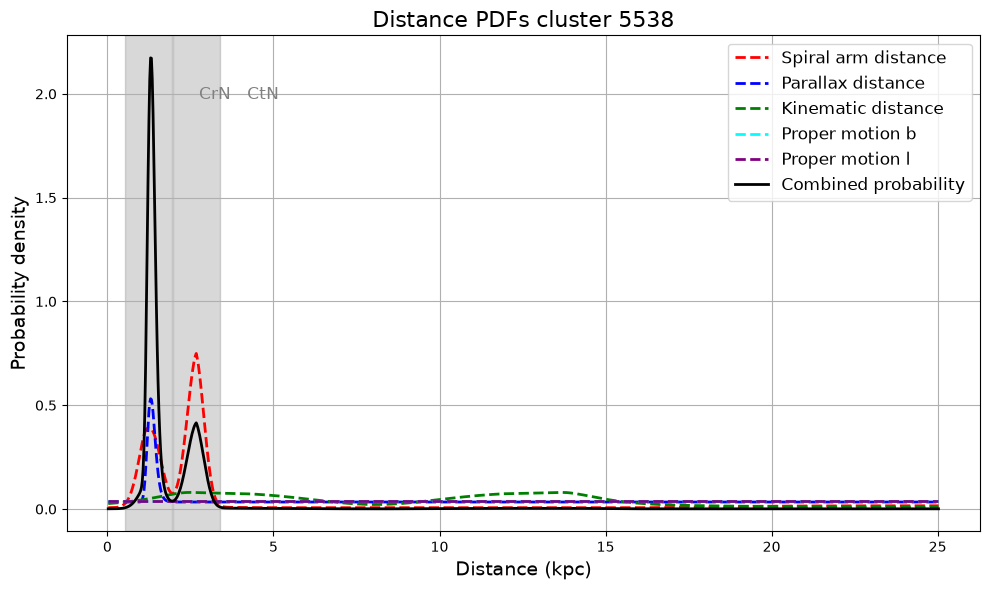

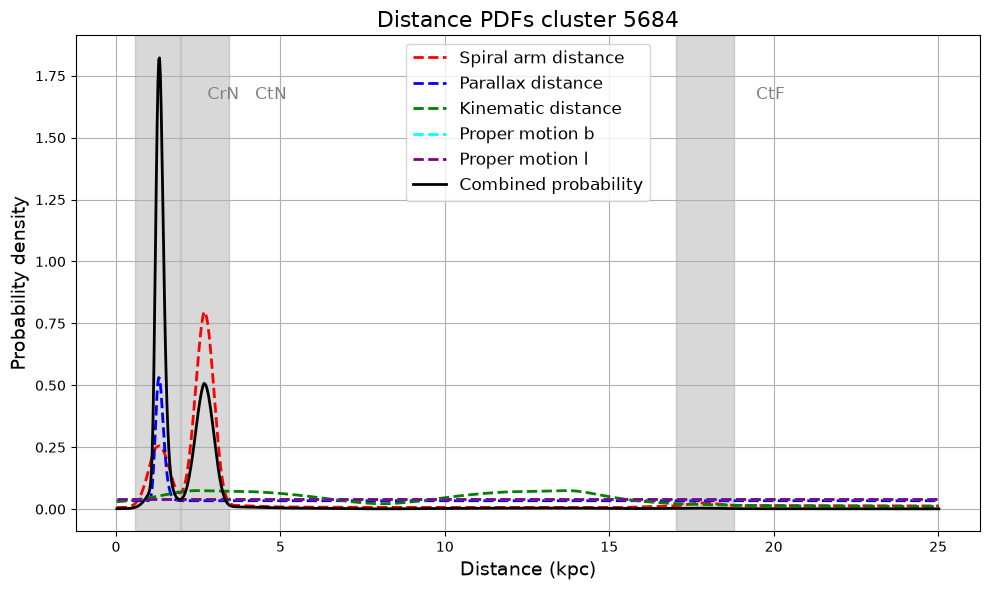

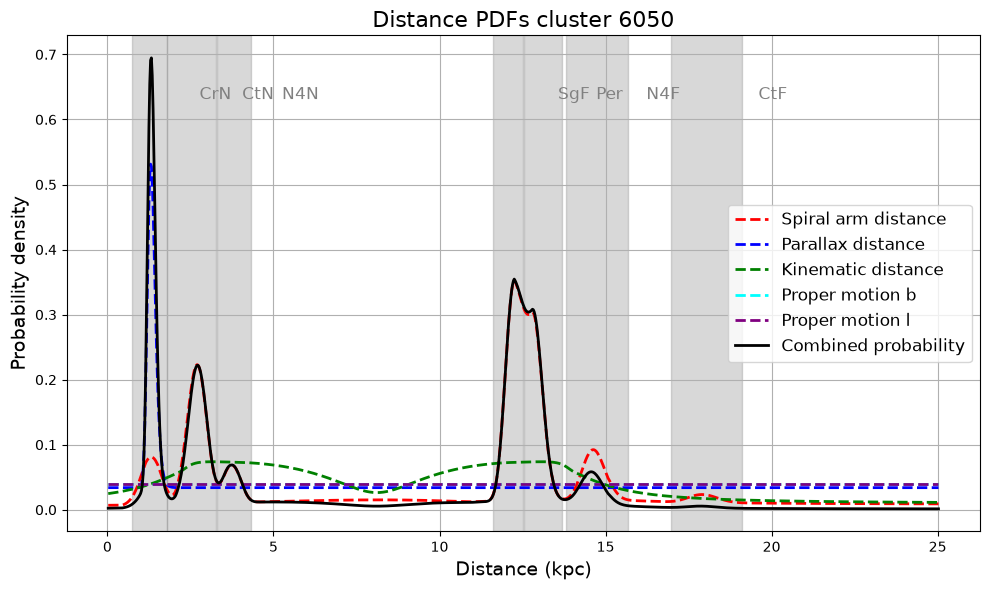

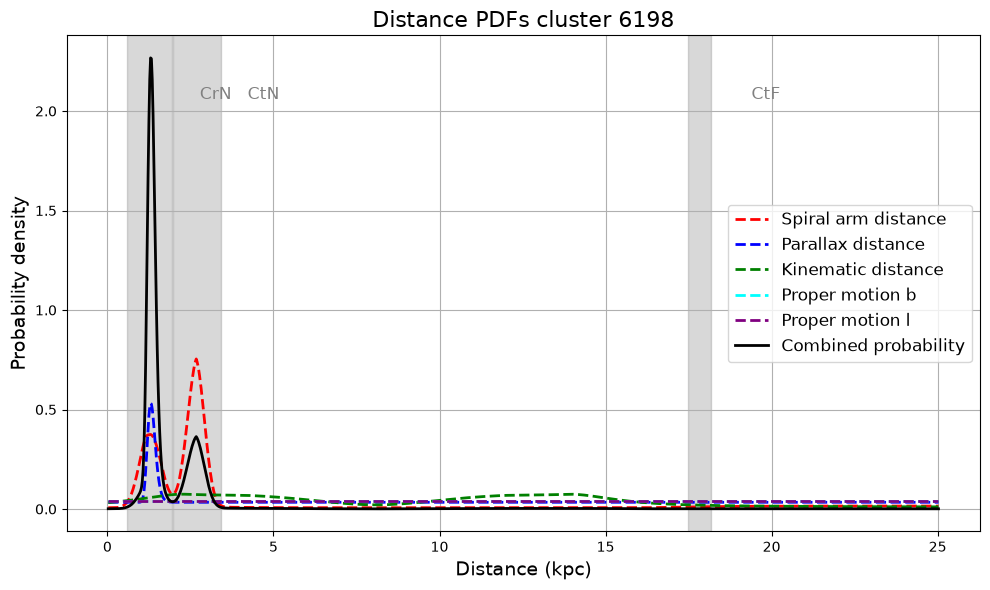

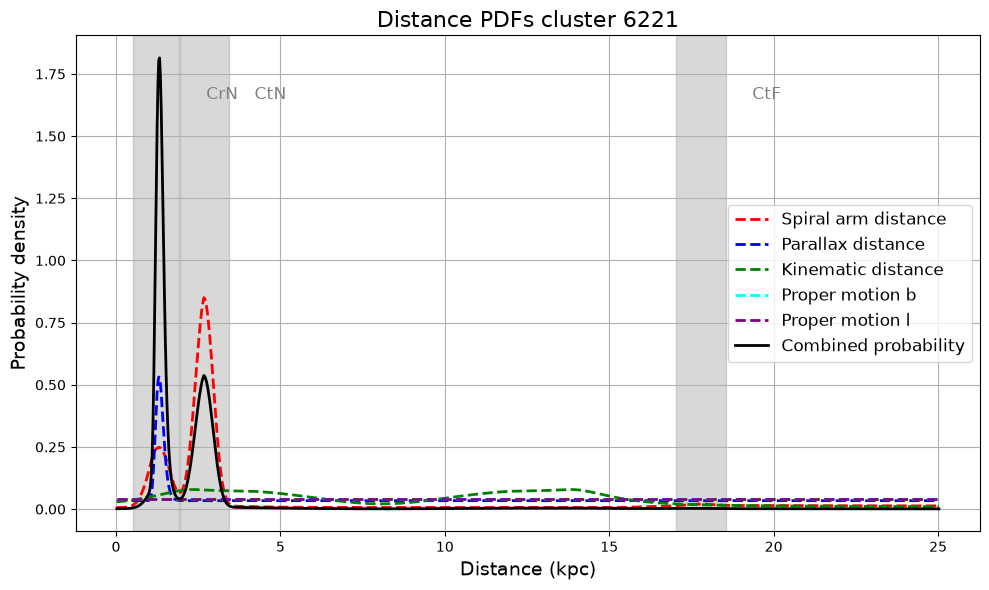

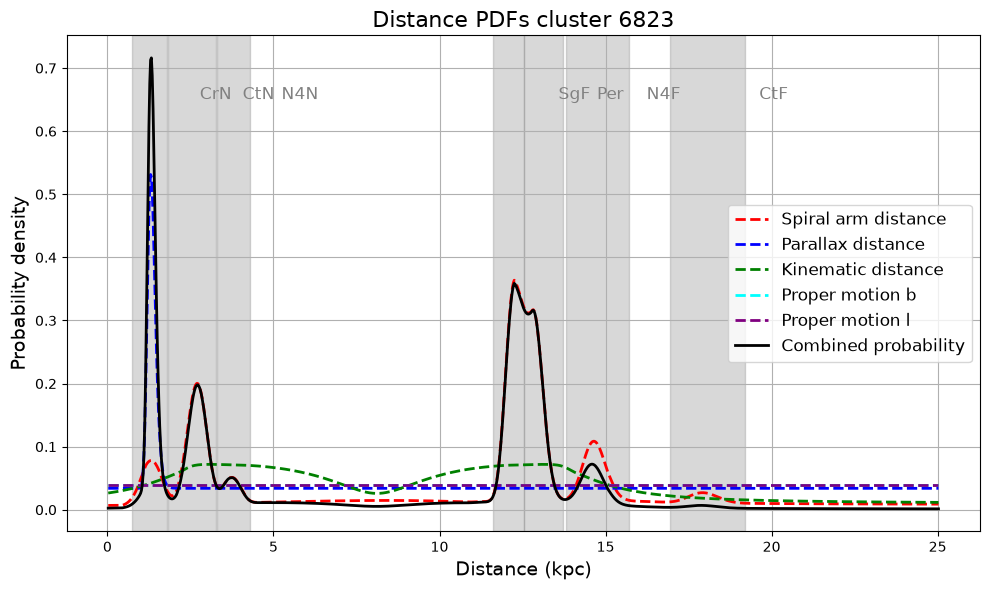

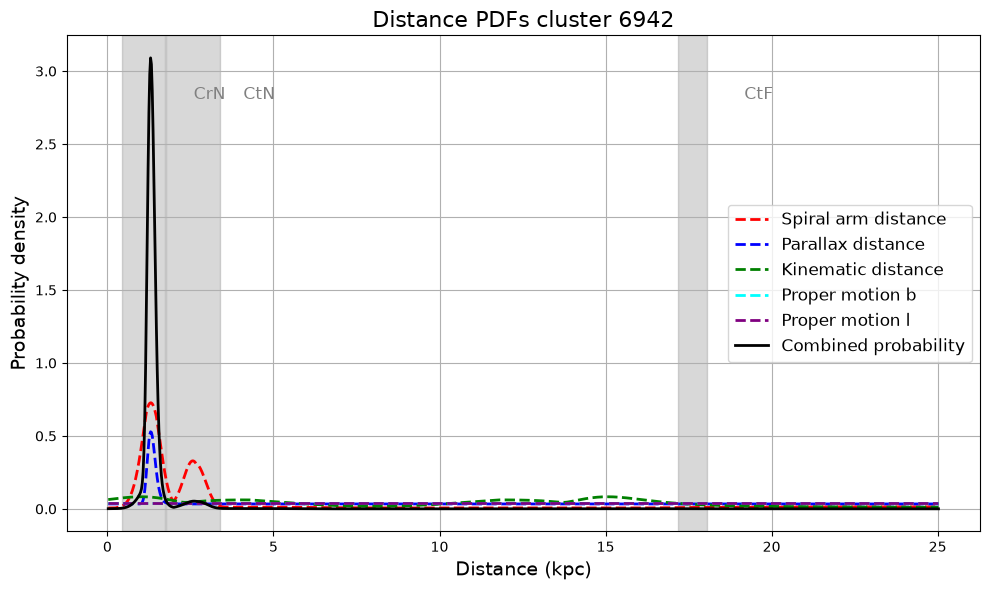

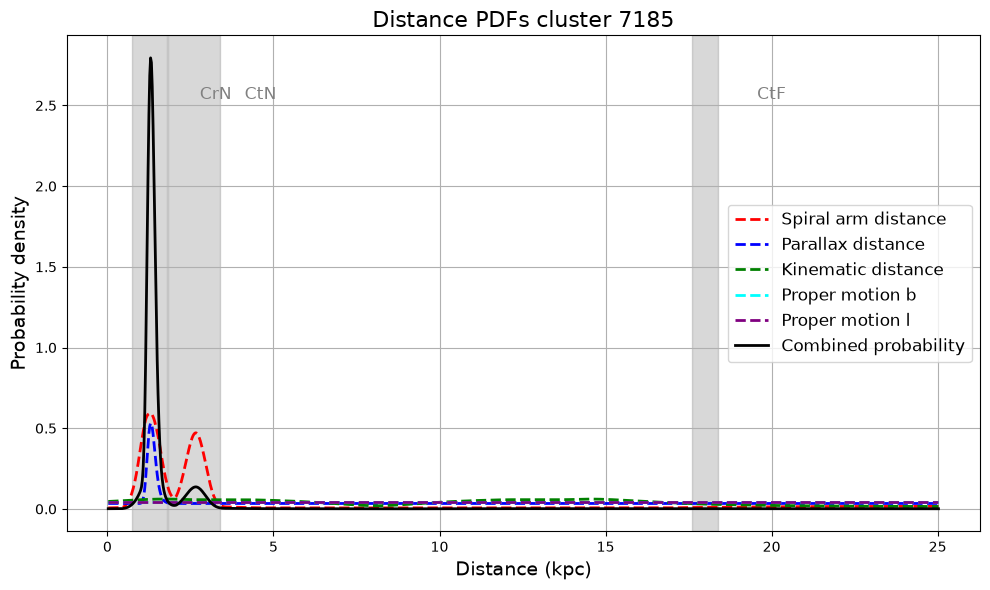

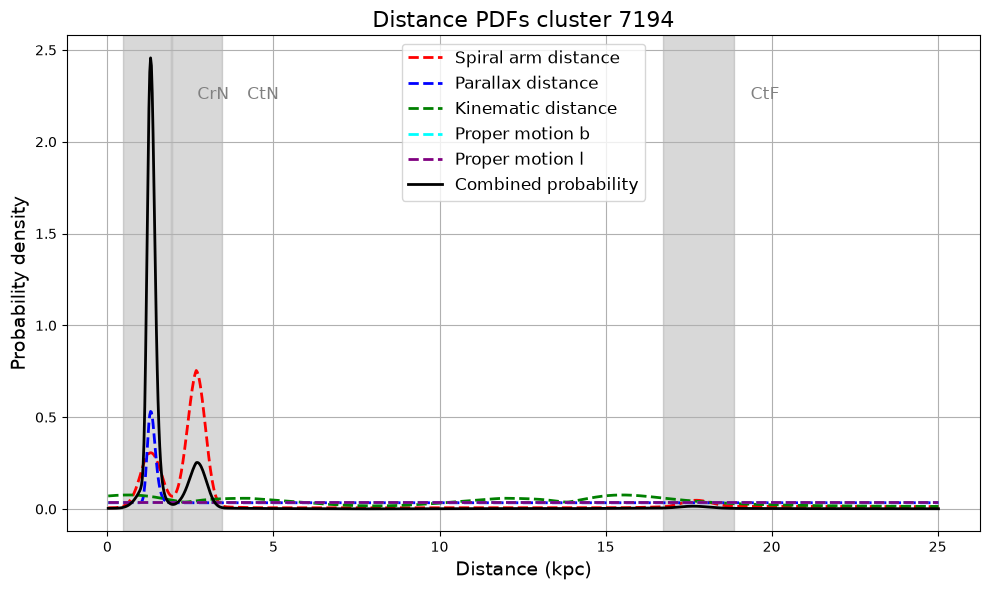

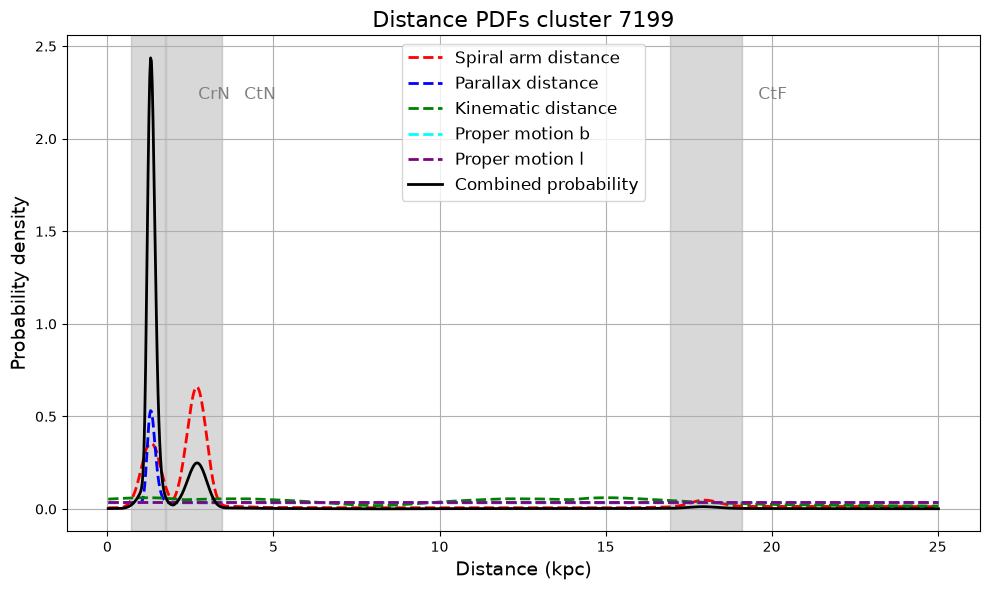

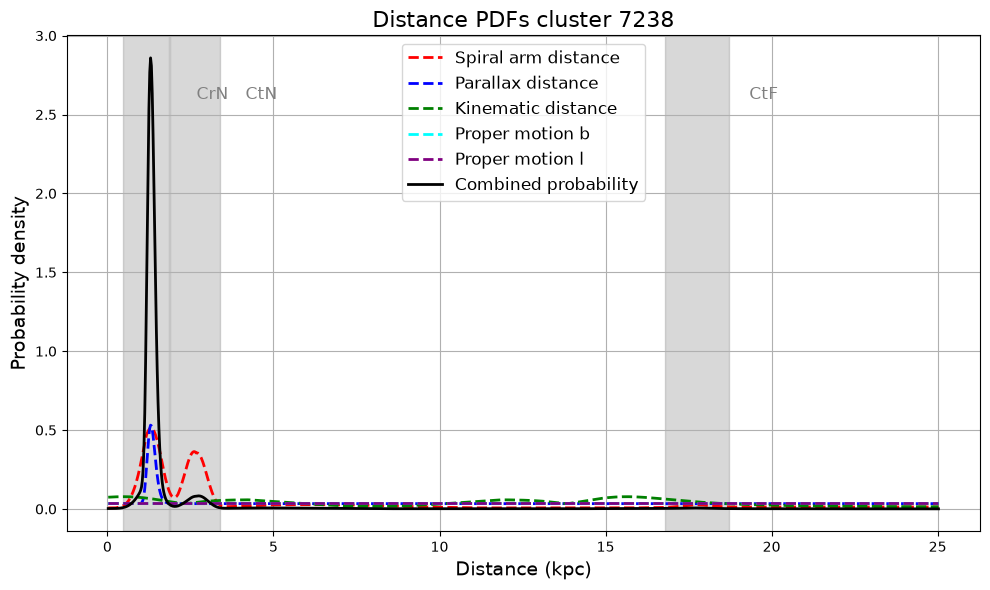

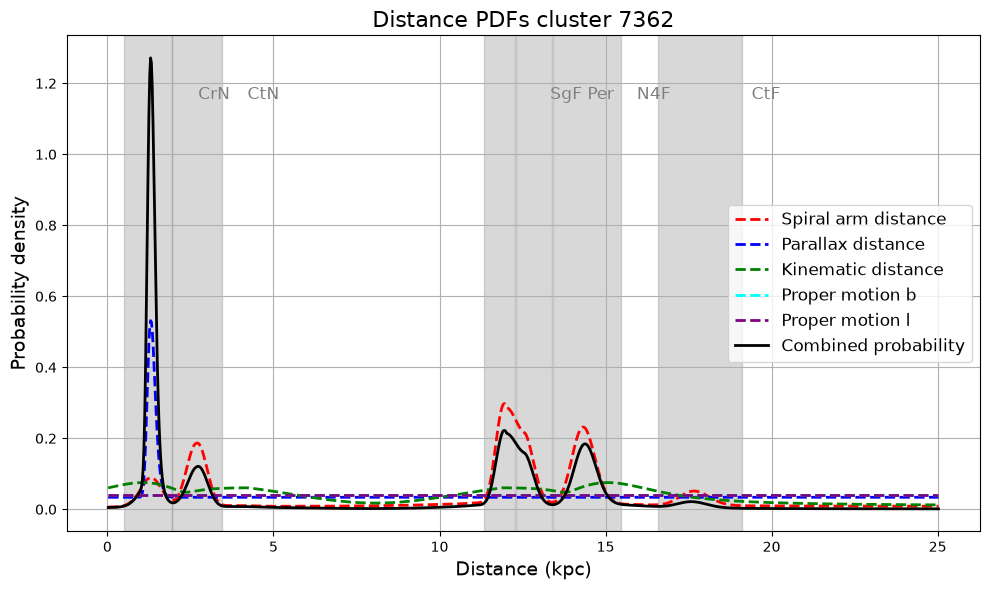

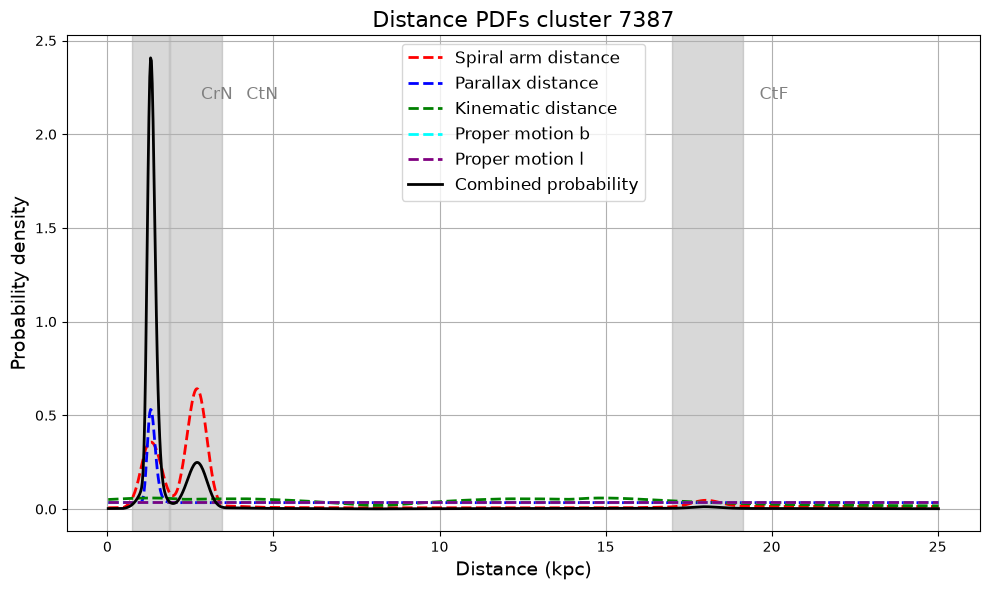

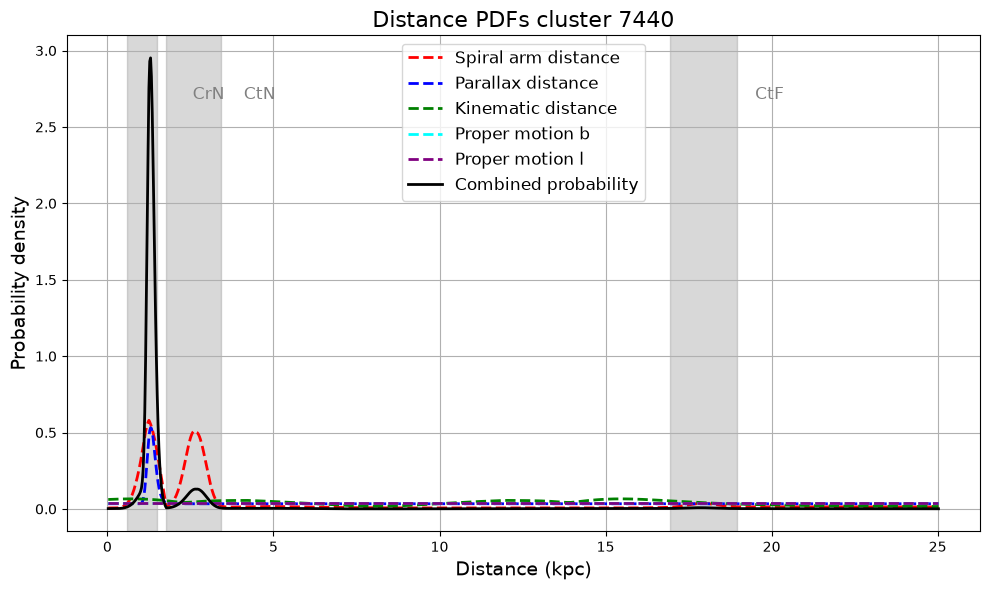

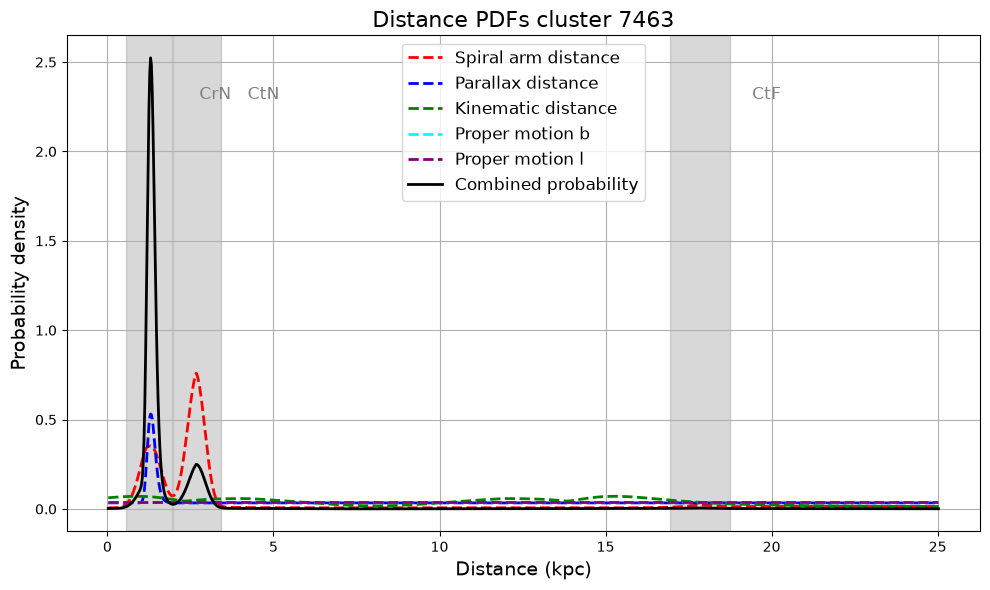

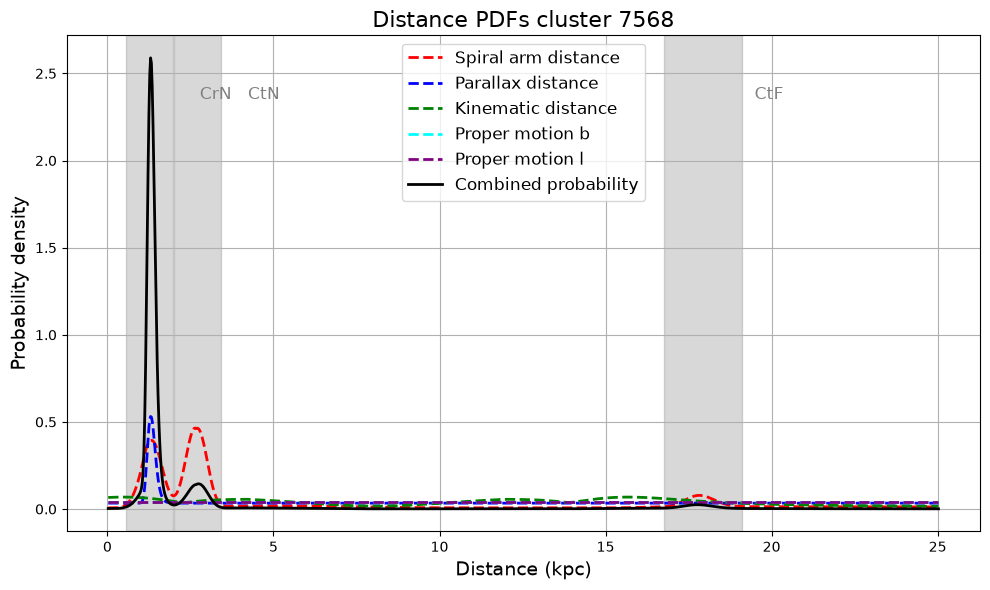

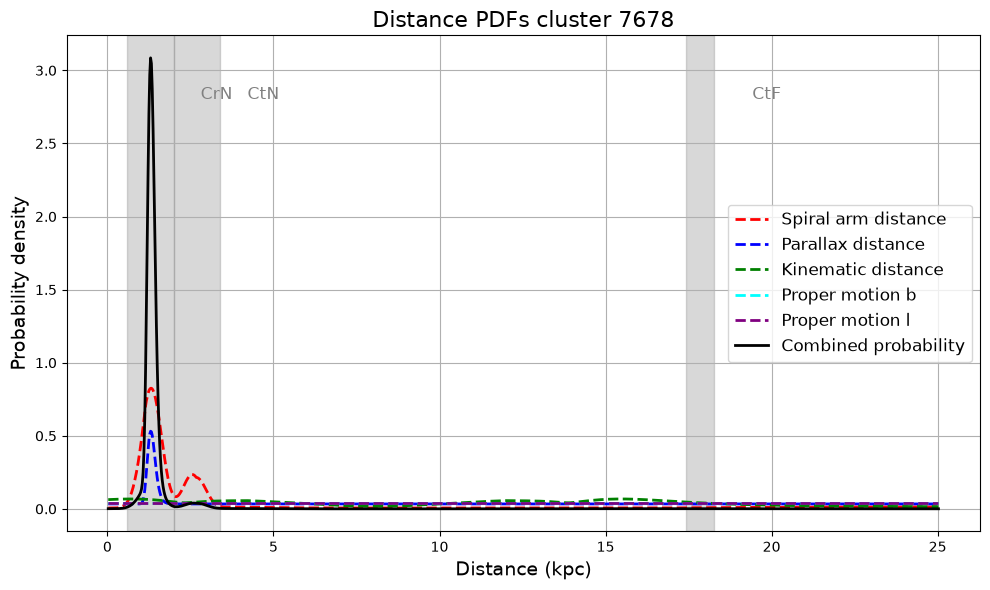

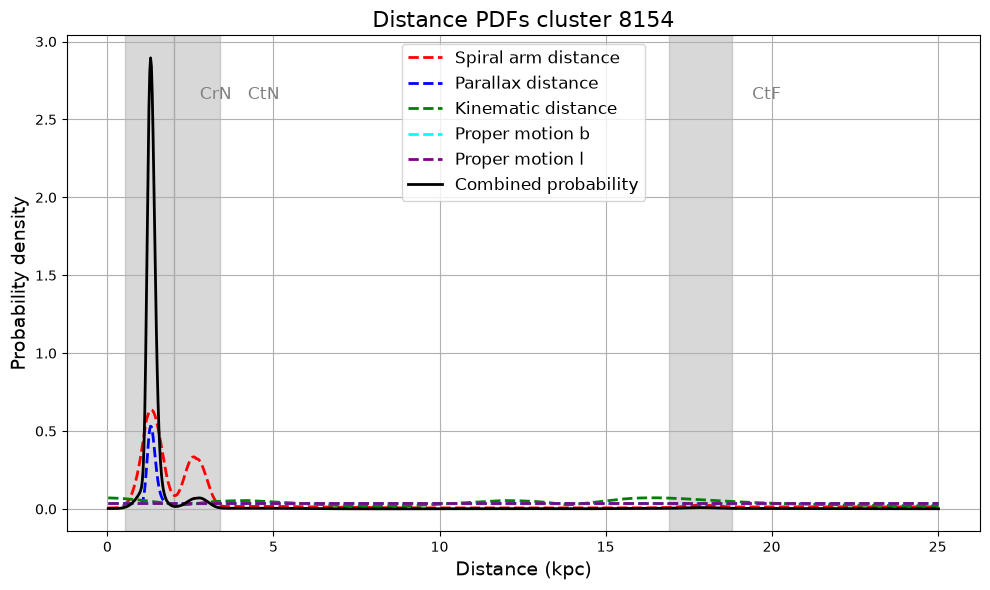

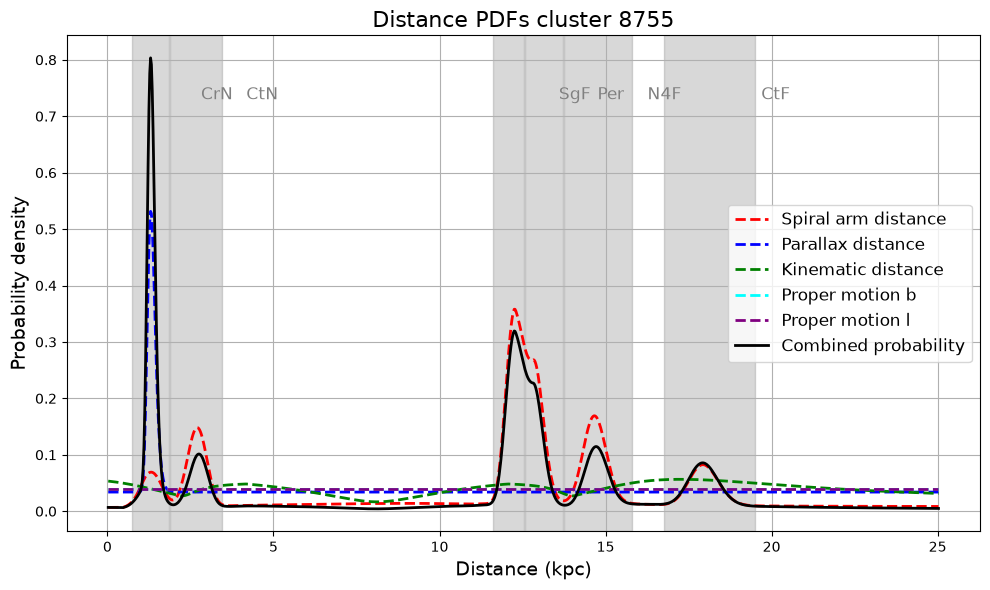

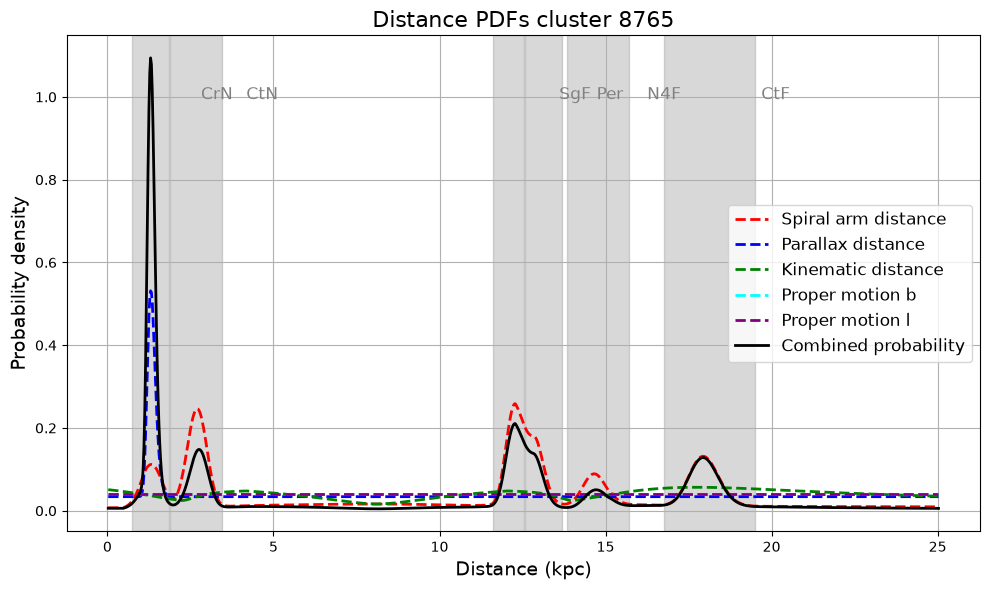

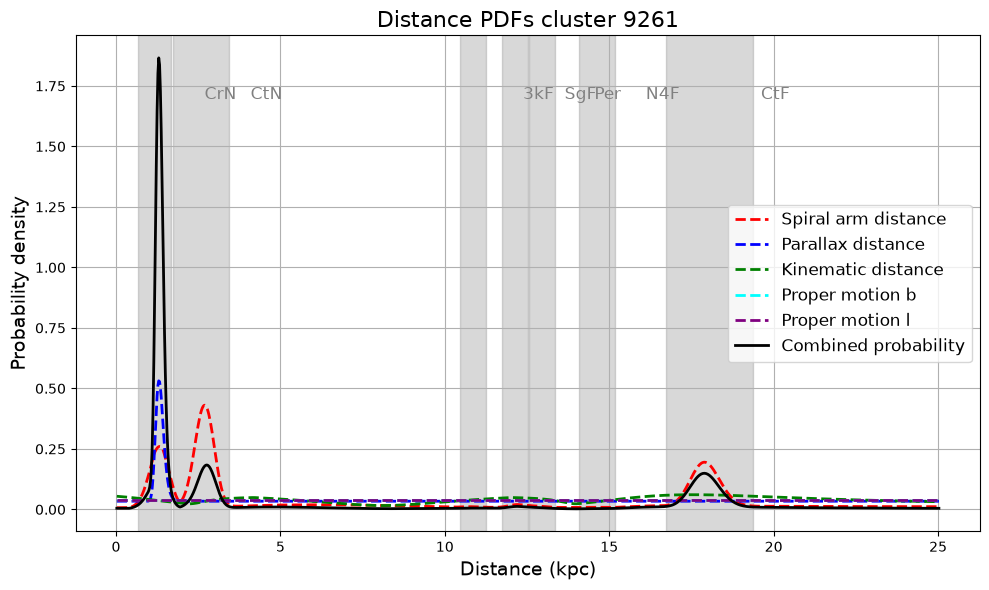

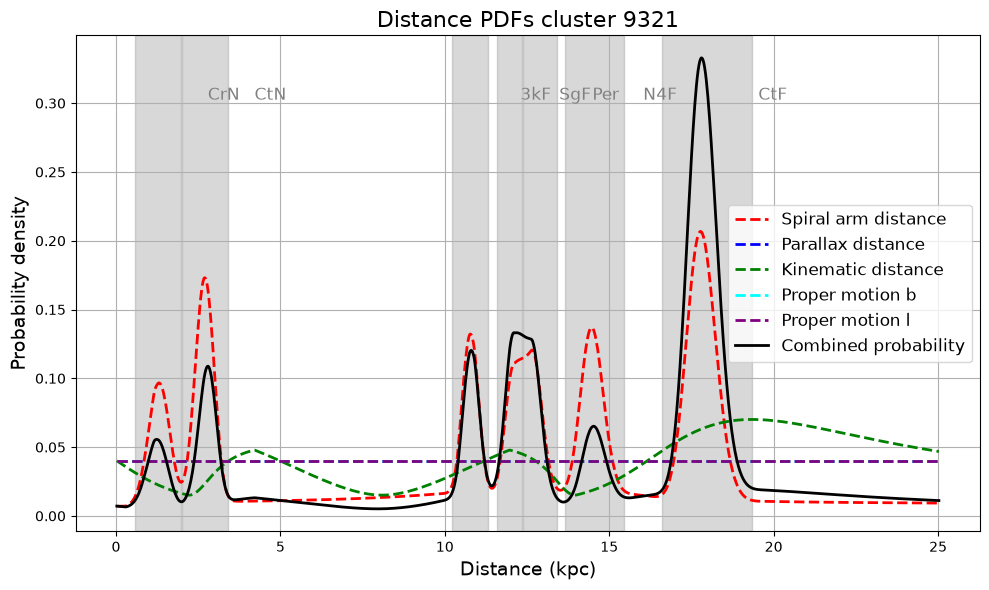

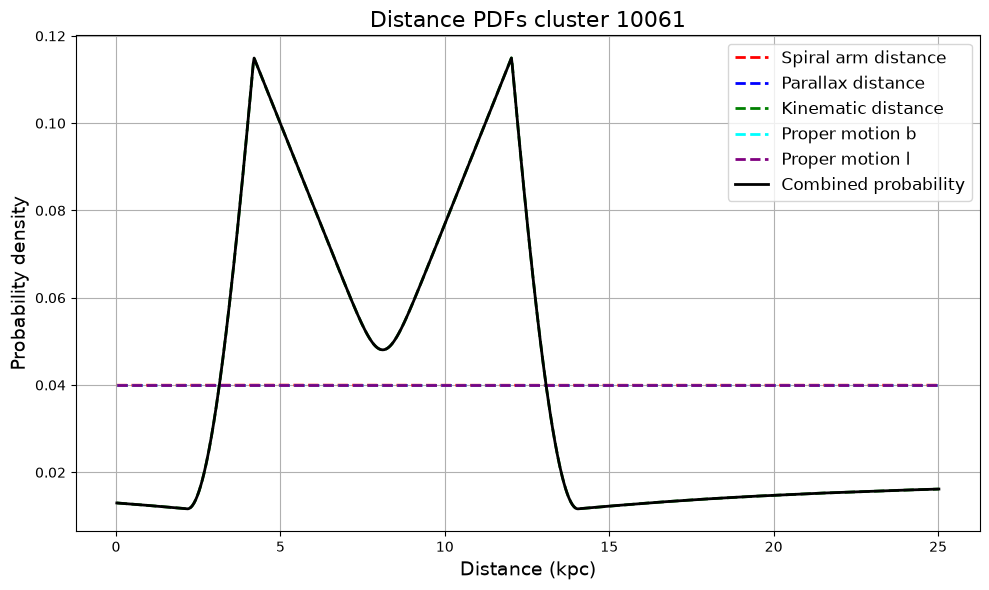

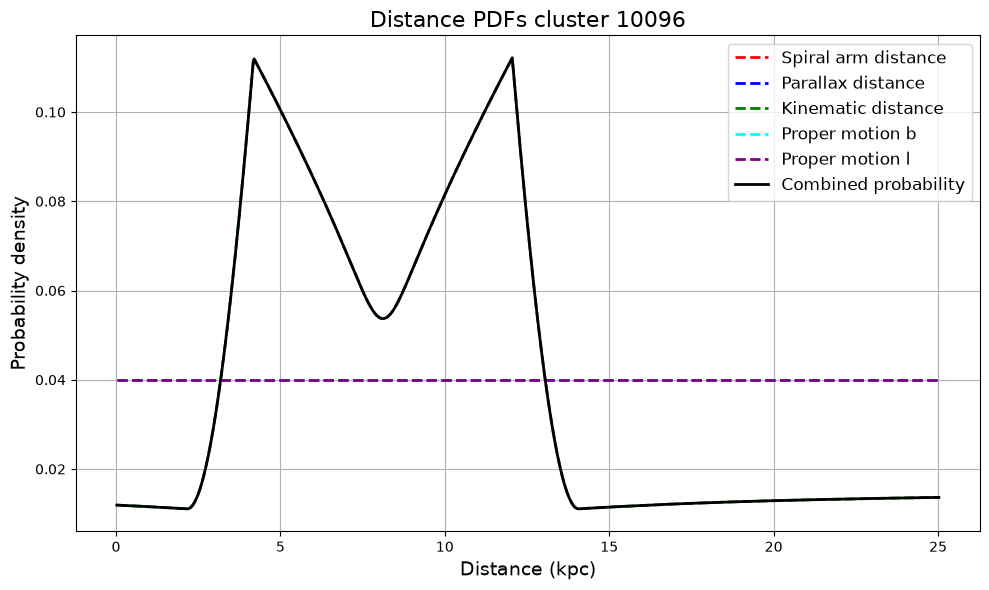

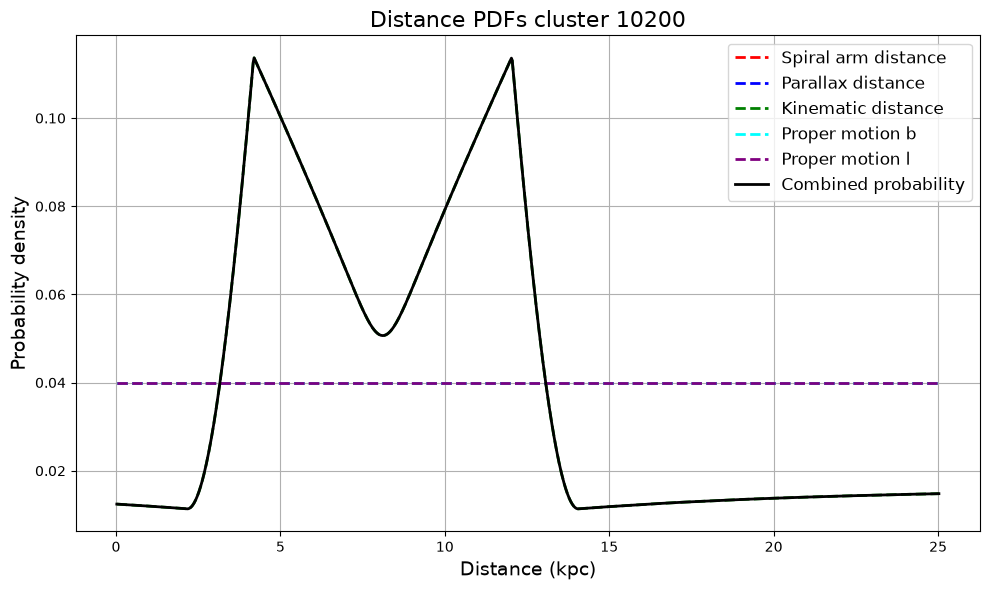

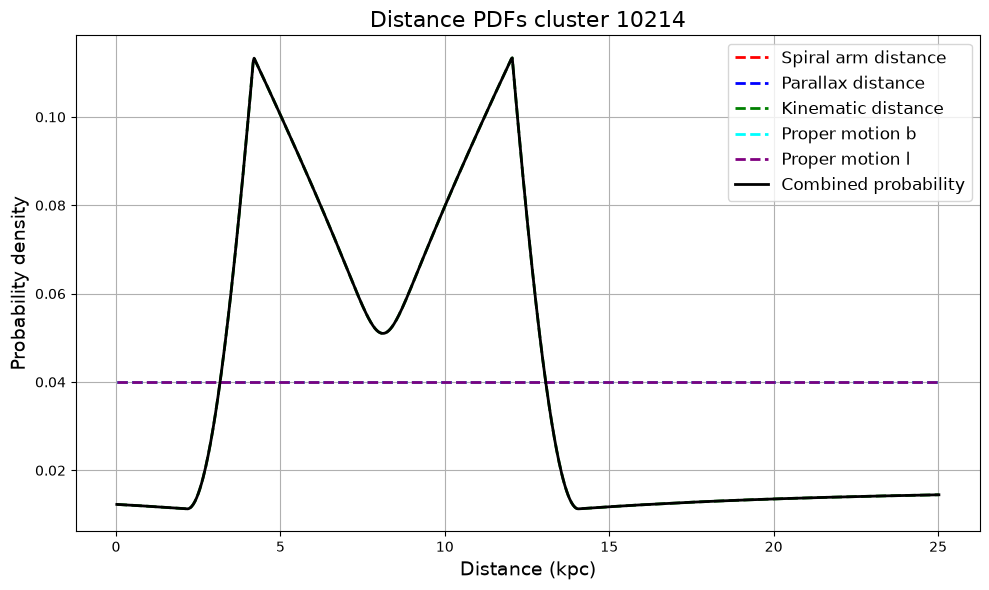

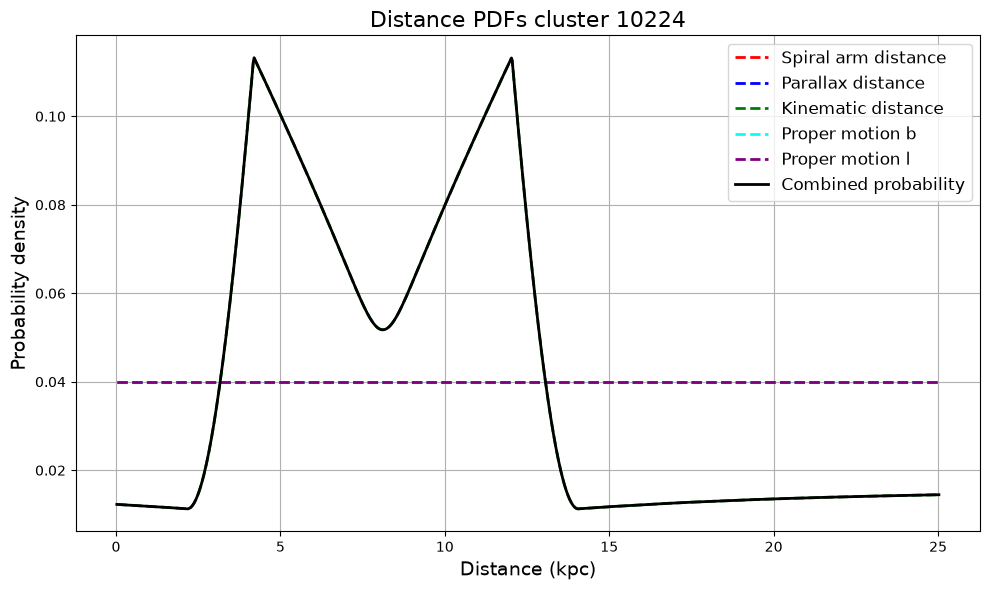

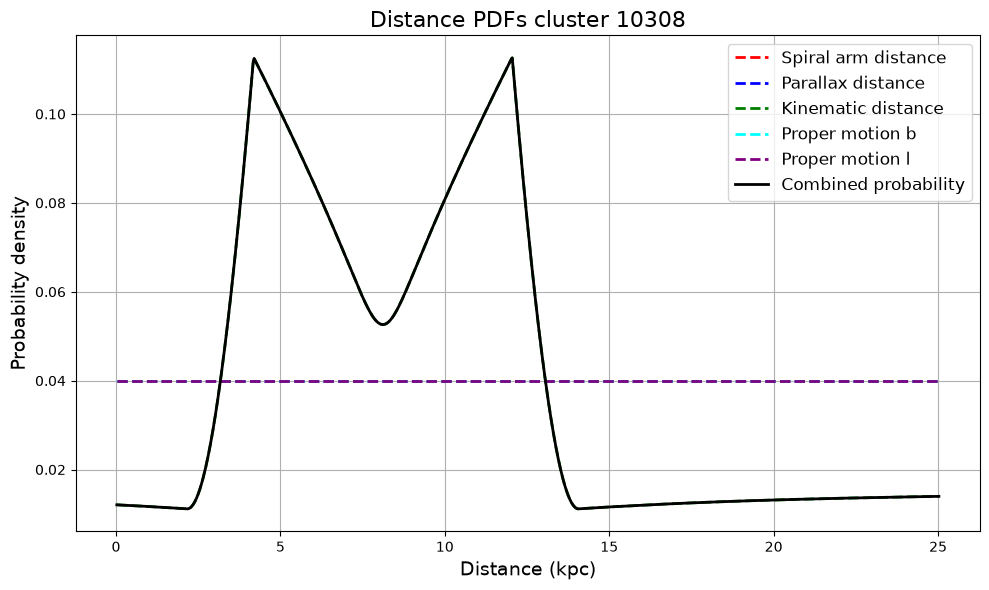

In [474]:
# Plots the distances
# Run fearlessly and optionally

def plot_distance_pdf(cluster_number,distance_dir):

    data_final     = np.loadtxt(distance_dir + f'{cluster_number}_final_distance_pdf.dat', skiprows=2)  # Skip header: "D(kpc) Probability"
    distances1     = data_final[:, 0]   # Column 1: D(kpc)
    probabilities1 = data_final[:, 1]  # Column 2: Probability

    data_spiral    = np.loadtxt(distance_dir + str(cluster_number)+'_arm_latitude_pdf.dat', skiprows=2, usecols=(0, 1))
    distances2     = data_spiral[:, 0]
    probabilities2 = data_spiral[:, 1]

    data_parallax  = np.loadtxt(distance_dir + str(cluster_number)+'_parallaxes_pdf.dat', skiprows=2)
    distances3     = data_parallax[:, 0]
    probabilities3 = data_parallax[:, 1]

    data_kinematic = np.loadtxt(distance_dir + str(cluster_number)+'_kinematic_distance_pdf.dat', skiprows=2)
    distances4     = data_kinematic[:, 0]
    probabilities4 = data_kinematic[:, 1]

    data_latitude  = np.loadtxt(distance_dir + str(cluster_number)+'_pm_bee_distance_pdf.dat', skiprows=2)
    distances5     = data_latitude[:, 0]
    probabilities5 = data_latitude[:, 1]

    data_longitude = np.loadtxt(distance_dir + str(cluster_number)+'_pm_ell_distance_pdf.dat', skiprows=2)
    distances6     = data_longitude[:, 0]
    probabilities6 = data_longitude[:, 1]
    
    arm_ranges = []
    arm_file = distance_dir + str(cluster_number) + '_arm_ranges.dat'
    with open(arm_file, 'r') as f:
        for line in f:
            if line.strip().startswith('!') or not line.strip():
                continue
            parts = line.split()
            start, end, name = float(parts[0]), float(parts[1]), parts[2]
            if start > 0 and end > 0:
                arm_ranges.append((start, end, name))

# Plotting
    plt.figure(figsize=(10, 6))
    
    ymax = max(probabilities1)  # Adjust if you'd rather base it on other curves or overall max

    for start, end, name in arm_ranges:
    # Shading (transparent and no legend entry)
        plt.axvspan(start, end, color='gray', alpha=0.3, zorder=0)

    # Label the spiral arm at the midpoint
        midpoint = (start + end) / 2
        plt.text(midpoint+2, ymax * 0.9, name, fontsize=12, ha='center', va='bottom', color='gray')
    
    plt.plot(distances2, probabilities2, label='Spiral arm distance', color='red', lw=2, linestyle='--')
    plt.plot(distances3, probabilities3, label='Parallax distance', color='blue', lw=2, linestyle='--')
    plt.plot(distances4, probabilities4, label='Kinematic distance', color='green', lw=2, linestyle='--')
    plt.plot(distances5, probabilities5, label='Proper motion b', color='cyan', lw=2, linestyle='--')
    plt.plot(distances6, probabilities6, label='Proper motion l', color='purple', lw=2, linestyle='--')
    plt.plot(distances1, probabilities1, label='Combined probability', color='black', lw=2)

    plt.xlabel('Distance (kpc)', fontsize=14)
    plt.ylabel('Probability density', fontsize=14)
    plt.title(f'Distance PDFs cluster {cluster_number}', fontsize=16)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

for id in cluster_ids:
    plot_distance_pdf(id, distance_dir)

In [475]:
# Initialisess stuff
# Run fearlessly

os.chdir(clusters_path)

# Constants
a1, a2, a3 = 1.0077, 0.0394, 0.0071  # Brand & Blitz (1993)
theta0     = 236.0              # km/s
R0         = 8.15               # kpc
omega0     = theta0 / R0
dtor       = pi / 180

# Initialize outputs
n              = len(df)
R              = np.zeros(n)
Vcalc          = np.zeros(n)
d_near         = np.zeros(n)
d_far          = np.zeros(n)
distance       = np.full(n, np.nan)
dist_method    = np.zeros(n, dtype=int)

In [476]:
# Full rotation curve code
# Run fearlessly

# Step 1: Rotation Curve + Near/Far Distance Calculation
for i in range(n):
    l, b, V = df['x_cen'][i], df['y_cen'][i], df['v_cen'][i]/1000
    
    Ri = 0.5
    count = 0
    while True:
        count +=1
        Ri += 0.01
        wi = omega0 * ((a1 * (Ri/R0)**(a2 - 1)) + a3 * (R0 / Ri))
        Vtest = R0 * (wi - omega0) * sin(radians(l)) * cos(radians(b))
        if abs(Vtest - V) < 0.4:
            break

        if count > 1e6:
            count = 0
            Ri = 0.3
            break
    
    R[i] = Ri
    Vcalc[i] = Vtest

    A = cos(radians(b))**2
    B = 2 * R0 * cos(radians(b)) * cos(radians(l))
    C = R0**2 - Ri**2
    delta = B**2 - 4 * A * C

    if delta <= 0:
        d1 = d2 = R0 * cos(radians(l)) / cos(radians(b))
    else:
        sqrt_delta = sqrt(delta)
        d1 = -( -B + sqrt_delta ) / (2 * A)
        d2 = -( -B - sqrt_delta ) / (2 * A)

    d_near[i], d_far[i] = min(d1, d2), max(d1, d2)

    # Outer Galaxy check
    if R[i] >= R0 or d_near[i] <= 0:
        distance[i] = d_far[i]
        dist_method[i] = 2  # Outer Galaxy
    #print(i)
print("Step 1 cleared")

# Step 2: Tangent Point Method
# Apply only to unresolved sources (dist_method = 0)
for i in range(n):
    if dist_method[i] != 0:
        continue
    l = df['x_cen'][i]
    V = df['v_cen'][i]
    tan_vel = theta0 * sin(radians(l))
    if abs(V - tan_vel) < 10 and (d_far[i] - d_near[i]) <= 1.0:
        distance[i] = (d_near[i] + d_far[i]) / 2
        dist_method[i] = 3  # Tangent method
print("Step 2 cleared")

# Step 3: Scale Height Method
# Still unresolved sources
for i in range(n):
    if dist_method[i] != 0:
        continue
    b = df['y_cen'][i]
    z = d_far[i] * 1000 * tan(radians(b))  # pc
    if abs(z) > 120:
        distance[i] = d_near[i]
        dist_method[i] = 4  # Scale height method
print("Step 3 cleared")

# Step 4: Append Results
df['R_GC'] = R
df['d_near'] = d_near
df['d_far'] = d_far
df['distance'] = distance
df['dist_method'] = dist_method

Step 1 cleared
Step 2 cleared
Step 3 cleared


In [477]:
# Function definition
# Run fearlessly

def determine_distance_assignment(txt_path, d_near, d_far):
    components = []

    with open(txt_path, 'r') as f:
        lines = f.readlines()

    # Filter lines that contain "Probability component"
    prob_lines = [line.strip() for line in lines if line.strip().startswith("Probability component")]

    for line in prob_lines:
        parts = line.split()
        try:
            dist = float(parts[3])
            prob = float(parts[5])
            components.append((dist, prob))
        except (IndexError, ValueError):
            continue

    if not components:
        raise ValueError("No valid probability components found.")

    # Get distance of component with highest probability
    best_dist, _ = max(components, key=lambda x: x[1])
    #print(best_dist)
    
    all_distances = [comp[0] for comp in components]
    min_distance = min(all_distances)
    max_distance = max(all_distances)

    if abs(best_dist - d_near) <= abs(best_dist - d_far):
            return 'near'
    else:
            return 'far'

prt_dir = '/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/'  # Update if needed
final_distances = []
distance_flags = []  # Optional: stores 'near' or 'far'

In [478]:
# Selects near or far distances
# Run fearlessly

for idx, row in df.iterrows():
    obj_id = int(row['_idx'])
    prt_file = os.path.join(prt_dir, f"{obj_id}.prt")

    if row['R_GC'] < R0:

        try:
            choice = determine_distance_assignment(prt_file, row['d_near'], row['d_far'])
            if choice == 'near':
                final_distances.append(row['d_near'])
                distance_flags.append('near')
            else:
                final_distances.append(row['d_far'])
                distance_flags.append('far')
        except Exception as e:
            print(f"Warning: Failed to process {prt_file} due to {e}")
            final_distances.append(np.nan)
            distance_flags.append('error')

    else:
        final_distances.append(row['d_far'])
        distance_flags.append('No_KDA')

df['distance'] = final_distances
df['distance_flag'] = distance_flags  # Optional for debugging
#df['structure_type'] = df['structure_type'].str.decode('utf-8').str.strip() 

In [479]:
# Initialise stuff and 
# Run fearlessly        
# --- Get the numbers of the clusters we work with ---
cluster_numbers = df['_idx']

with fits.open(mult_filename) as hdul:
    raw_data = hdul[0].data


# --- Load COLTE densities ---
has_COLTE = False
try:
    if os.path.exists(COLTE_N13_file):
        with fits.open(COLTE_N13_file) as hdul_COLTE_N13:
            data_COLTE_N13 = hdul_COLTE_N13[0].data
            header_COLTE_N13 = hdul_COLTE_N13[0].header
        has_COLTE = True
    else:
        raise FileNotFoundError
except FileNotFoundError:
    print(f"Warning: {COLTE_N13_file} not found. Using all-True mask.")
    # Create a dummy all-True mask of compatible shape
    # You must already have a known shape, e.g., from another array
    colte_masked = np.ones_like(data, dtype=bool)

In [480]:
## Edit 12/08. Run this for X factor masses and don't run the cell below. That will be for COLTE only.

if isotopologue == "13CO":
    nonzero_pixels = df['area_exact']
    total_flux     = df['flux'] * CDELT3

    if CDELT3 > 100:
        total_flux = total_flux /1000

    for i in range(len(cluster_numbers)):
        print(df['_idx'][i])
        print("integrated flux:", total_flux[i])
        print("number of pixels:", nonzero_pixels[i])

else:
    nonzero_pixels = []
    total_flux     = []

    for num in cluster_numbers:
        if num == 0:
            new_data = np.where(mask, 1, 0) # Replace cluster 0 voxels with 1, keep background (-1) untouched
        if has_COLTE == False:
            mask = (data == num)
        else:
            mask = (data == num) & (~np.isnan(data_COLTE_N13))
        new_data = np.where(mask, raw_data, 0)

        new_data_good = new_data[~np.isnan(new_data)]
        pixels_nonzero = np.count_nonzero(new_data_good)
        integ_flux = np.sum(new_data_good) * np.abs(CDELT3)
        if np.abs(CDELT3) > 100:
            integ_flux = integ_flux / 1000

        print(num)
        total_flux.append(integ_flux)
        nonzero_pixels.append(pixels_nonzero)
        print("cluster pixels sum:", new_data.sum()) 
        print("integrated flux:", integ_flux)
        print("number of pixels:", pixels_nonzero)



df['total_flux']   = total_flux
df['pixel_number'] = nonzero_pixels

239
cluster pixels sum: 1714.1307
integrated flux: 857.0653685976699
number of pixels: 478
391
cluster pixels sum: 50055.395
integrated flux: 25027.697264028433
number of pixels: 7615
709
cluster pixels sum: 48497.41
integrated flux: 24248.705076578128
number of pixels: 6105
809
cluster pixels sum: 817.41
integrated flux: 408.70498654619354
number of pixels: 223
955
cluster pixels sum: 144650.83
integrated flux: 72325.41405788621
number of pixels: 21320
1037
cluster pixels sum: 64161.57
integrated flux: 32080.785154203506
number of pixels: 6647
1062
cluster pixels sum: 2140.1592
integrated flux: 1070.0795897754876
number of pixels: 506
1202
cluster pixels sum: 1338.1343
integrated flux: 669.0671386291939
number of pixels: 364
1424
cluster pixels sum: 2295.328
integrated flux: 1147.6639403564757
number of pixels: 375
1551
cluster pixels sum: 6301.0493
integrated flux: 3150.524658002147
number of pixels: 1002
1710
cluster pixels sum: 2323.845
integrated flux: 1161.9224852774412
number of

In [364]:
nonzero_pixels = []
total_flux     = []
COLTE_Mass     = []

for num in cluster_numbers:
    mask = (data == num)
    new_data = np.where(mask, raw_data, 0)

    # Only calculate COLTE-based mass if we have the file
    colte_masked = np.where(mask, data_COLTE_N13, 0)
    colte_mass   = np.nansum(colte_masked) * np.abs(header_COLTE_N13['CDELT3'])
    if header_COLTE_N13['CUNIT3'] == 'm/s':
            colte_mass = colte_mass / 1000


    new_data_good = colte_masked[~np.isnan(colte_masked)]
    pixels_nonzero = np.count_nonzero(new_data_good)
    integ_flux = np.sum(new_data_good) * CDELT3

    if header['CUNIT3'] == 'm/s':
        integ_flux = integ_flux / 1000

    print(num)

    total_flux.append(integ_flux)
    nonzero_pixels.append(pixels_nonzero)
    COLTE_Mass.append(colte_mass)
    print("cluster pixels sum:", new_data.sum())
    print("integrated flux:", integ_flux)
    print("number of pixels:", pixels_nonzero)
    print("colte total density:", colte_mass)

# Append the columns to the df and verify it

df['total_flux']   = total_flux # actually integrated
df['pixel_number'] = nonzero_pixels 
df['COLTE_Density']   = COLTE_Mass
df

NameError: name 'data_COLTE_N13' is not defined

In [481]:
# Chooses between AGAL distance for clusters with matches and best distance for those without
# Looks like AGAL distances are strings! turn them to floats first.
# Run fearlessly

final_distance = []
for i in range(len(df)):
    if df['has_match'][i] and df['AGAL_distance'][i] != '---':
        final_distance.append(float(df['AGAL_distance'][i]))
    else:
        final_distance.append(df['distance'][i])

df['final_distance'] = final_distance

In [482]:
# Spreadsheet calculations
# Run fearlesly

df['distance_cm'] = df['final_distance'] * 3.086 * pow(10,21)
df['Mean_flux']   =df['total_flux'] / df['pixel_number'] # actually integrated, not mean

# Constants
if isotopologue == "12CO":
    X_factor = 2 * pow(10,20)  
else:
    X_factor = 5.78 * pow(10,20)  
    
mH2            = 1.67 * 2.72 * pow(10,-24)
Msol           = 2 * pow(10,33)
pixel_area_arc = pow(8.33 *3.6 , 2)
arc_2_sr       = pow(np.pi / 180 / 3600, 2)

df['density']= X_factor * df['Mean_flux']

# Ellipse masses
df['semi_major_deg']= df['major_arcsec'] / 7200  # Divide by 7200 to turn major to semi-major too
df['semi_minor_deg']= df['minor_arcsec'] / 7200
df['semi_major_cm'] = df['semi_major_deg'] * df['distance_cm'] * np.pi / 180 * 2.354
df['semi_minor_cm'] = df['semi_minor_deg'] * df['distance_cm'] * np.pi / 180 * 2.354
df['NH2_ellipse']   = df['density'] * np.pi * df['semi_major_cm'] * df['semi_minor_cm']
df['M_ellipse_g']   = df['NH2_ellipse'] * mH2


# Pixel area masses
df['angular_size_sr']       = df['pixel_number'] * pixel_area_arc * arc_2_sr
df['area_cm2_pixel_method'] = df['angular_size_sr'] * pow(df['distance_cm'],2)
df['NH2_pixel']             = df['area_cm2_pixel_method'] * df['density']
df['M_pixel_g']             = df['NH2_pixel'] * mH2

df['M_ellipse_Sol']    = df['M_ellipse_g'] / Msol   
df['M_pixel_Sol']      = df['M_pixel_g'] / Msol
#df['M_COLTE_Sol_CO']   = df['COLTE_Density'] / Msol * pixel_area_arc * arc_2_sr * pow(df['distance_cm'],2) * mH2
#df['M_COLTE_Sol_H2']   = df['M_COLTE_Sol_CO'] / (8.5 / 10 ** 5) * (6.2 * df['R_GC'] + 18.7) 

In [483]:
# Formatting the df
# Run fearlessly

df['area_ellipse']   = df['area_ellipse'].round(1)  # Round to 1 decimal place
df['area_exact']     = df['area_exact'].round(1)
df['major_sigma']    = df['major_sigma'].round(1)
df['minor_sigma']    = df['minor_sigma'].round(1)
df['position_angle'] = df['position_angle'].round(1)
df['radius']         = df['radius'].round(1)
df['v_cen']          = df['v_cen'].round(2)
df['v_rms']          = df['v_rms'].round(2)
df['x_cen']          = df['x_cen'].round(3)
df['y_cen']          = df['y_cen'].round(3)
df['radius_arcsec']  = df['radius_arcsec'].round(1)
df['sigv_kms']       = df['sigv_kms'].round(2)
df['xcens']          = df['xcens'].round(3)
df['ycens']          = df['ycens'].round(3)
df['vcens']          = df['vcens'].round(3)
df['major_arcsec']   = df['major_arcsec'].round(1)
df['minor_arcsec']   = df['minor_arcsec'].round(1)
df['R_GC']           = df['R_GC'].round(2)
df['d_near']         = df['d_near'].round(2)
df['d_far']          = df['d_far'].round(2)
df['distance']       = df['distance'].round(2)
df['final_distance'] = df['final_distance'].round(2)


df['distance_cm']           = df['distance_cm'].apply(lambda x: f'{x:.2e}') # Write to format 1e7
df['Mean_flux']             = df['Mean_flux'].round(2)
df['density']               = df['density'].apply(lambda x: f'{x:.2e}')
df['semi_major_deg']        = df['semi_major_deg'].round(3)
df['semi_minor_deg']        = df['semi_minor_deg'].round(3)
df['semi_major_cm']         = df['semi_major_cm'].apply(lambda x: f'{x:.2e}')
df['semi_minor_cm']         = pd.to_numeric(df['semi_minor_cm']).apply(lambda x: f'{x:.2e}')
df['NH2_ellipse']           = df['NH2_ellipse'].apply(lambda x: f'{x:.2e}')
df['M_ellipse_g']           = df['M_ellipse_g'].apply(lambda x: f'{x:.2e}')
df['M_ellipse_Sol']         = df['M_ellipse_Sol'].apply(lambda x: f'{x:.2e}')
df['angular_size_sr']       = df['angular_size_sr'].apply(lambda x: f'{x:.2e}')
df['area_cm2_pixel_method'] = df['area_cm2_pixel_method'].apply(lambda x: f'{x:.2e}')
df['NH2_pixel']             = df['NH2_pixel'].apply(lambda x: f'{x:.2e}')
#df['M_COLTE_Sol_CO']        = df['M_COLTE_Sol_CO'].apply(lambda x: f'{x:.2e}')
#df['M_COLTE_Sol_H2']        = df['M_COLTE_Sol_H2'].apply(lambda x: f'{x:.2e}')
#df['COLTE_Density']         = df['COLTE_Density'].apply(lambda x: f'{x:.2e}')
df['M_pixel_g']             = df['M_pixel_g'].apply(lambda x: f'{x:.2e}')
df['M_pixel_Sol']           = df['M_pixel_Sol'].apply(lambda x: f'{x:.2e}')

In [484]:
# Save final result with proper structure types

if has_COLTE == True:
    csv_output        = mult_path +f"G{region}_{isotopologue}_COLTE_masses_snr3.csv"
df.to_csv(csv_output, index= False)

#df.to_csv(f'{dataset}_{region}_{isotopologue}_X_factor_masses_COLTE_pixelv2.csv', index= False)
#df.to_csv(f'{dataset}_{region}_{isotopologue}_sphere1_doubled_halfsigma_044noise_3D.csv', index= False)
#df.to_csv('out_01_mass.csv', index= False)
df_sub = df[df["sigv_kms"] > v_lim2 / 2.354]

#df_sub.to_csv(csv_output_sub, index= False)

# End of main code

2.4974721941354905
KstestResult(statistic=np.float64(0.015274949083503055), pvalue=np.float64(0.9998471708847518), statistic_location=np.float64(15000.0), statistic_sign=np.int8(1))
m = 1.0132707825512348*m2 + -0.04739205474485835


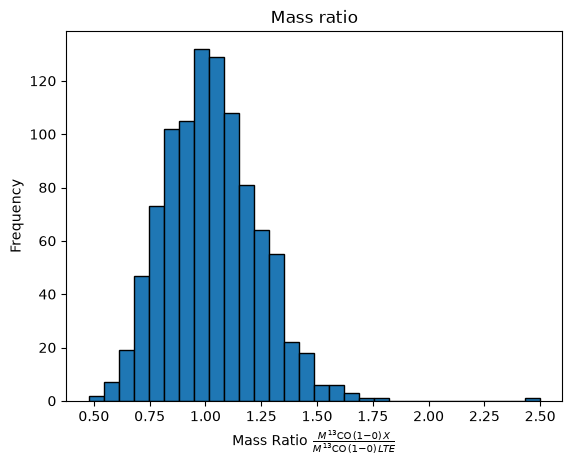

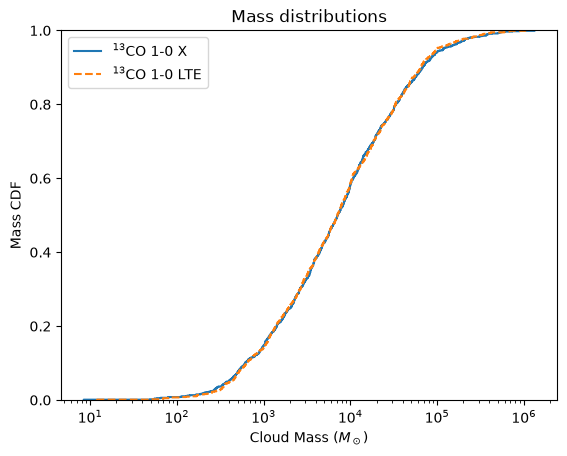

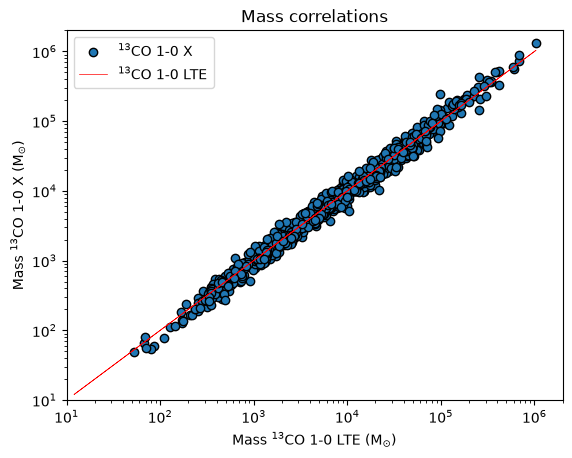

In [5]:
## Copied from BDC, I will use this to compare Mopra full X-factor vs Mopra full COLTE.


saveplot = False

df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/Mopra/13CO/Mopra_Full_Cloud_Catalogue_cleaned.csv')

mass_options = {
    1 : {
        "m2_col": "M_LTE_Sol",
        "xlabel": r"$\frac{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,LTE}$",
        "plottitles": 'Modified_Mopra_mass_LTE_snr0.png',
        "labels": r"$^{13}$CO 1-0 LTE",
        "axlabel": 'Mass $^{13}$CO 1-0 LTE (M$_{\odot}$)',
        "KStitles": "Corrected_Mopra_mass_LTE_snr0_KSTest.png",
        "title":'Mass_comparison_LTE_snr0.png'
    },

    2 : {
        "m2_col": "M_12CO_X_Sol",
        "xlabel": r"$\frac{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}{M\,^{12}\mathrm{CO}\,(1\!-\!0)\,X}$",
        "plottitles": 'Modified_Mopra_mass_12CO_X.png',
        "labels": r"$^{12}$CO 1-0 X",
        "axlabel": 'Mass $^{12}$CO 1-0 X (M$_{\odot}$)',
        "KStitles": "Corrected_Mopra_mass_12CO_KSTest.png",
        "title":'Mass_comparison_12CO.png'
    }
}


mode = 1


m = df_2['M_13CO_X_Sol'].dropna()

m2 = df_2[mass_options[mode]['m2_col']].dropna()

mask = (m>0) & (m2 >0)

m  = m[mask]
m2 = m2[mask]


equal_ratio = m / m2

mask2 = (equal_ratio < equal_ratio.max() +1)

equal_ratio = equal_ratio[mask2]
m = m[mask2]
m2 = m2[mask2]



bins = np.linspace(
equal_ratio.min(),
equal_ratio.max(),
int(np.sqrt(len(equal_ratio)))
)

plt.hist(equal_ratio, bins=bins, edgecolor='k')



plt.xlabel(f'Mass Ratio {mass_options[mode]["xlabel"]}')
plt.ylabel('Frequency')
plt.title(r'Mass ratio')

print(equal_ratio.max())

if saveplot == True:
    plt.savefig(mass_options[mode]['plottitles'])

print(stats.kstest(m, m2))

coeffs = np.polyfit(np.log10(m2), np.log10(m), 1)
slope = coeffs[0]
intercept = coeffs[1]
print(f"m = {slope}*m2 + {intercept}")


plt.figure()
ax = sns.ecdfplot(
    m,
    log_scale=True,
    label=r"$^{13}$CO 1-0 X",
    linestyle='-'
)

sns.ecdfplot(
    m2,
    log_scale=True,
    label=mass_options[mode]['labels'],
    linestyle='--',
    ax=ax
)
plt.title('Mass distributions')
plt.legend()

plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel('Mass CDF')
if saveplot == True:
    plt.savefig(mass_options[mode]['KStitles'])


label_choice = mass_options[mode]["labels"]
axlabel      = mass_options[mode]["axlabel"]

plt.figure()
plt.scatter(
    m2,
    m,
    edgecolor='k',
    label = r"$^{13}$CO 1-0 X")
plt.plot(
    m2,
    m2,
    color='red',
    label = label_choice,
    linewidth = 0.5
)
plt.ylabel('Mass $^{13}$CO 1-0 X (M$_{\odot}$)')
plt.xlabel(axlabel)
plt.xscale('log')
plt.xlim([10, 2000000])
plt.ylim([10, 2000000])
plt.yscale('log')
plt.title('Mass correlations')
plt.legend()

file_title = mass_options[mode]["title"]
if saveplot == True:
    plt.savefig(mass_options[mode]['title'])

In [600]:
len(m)

1000

In [601]:
print(m.min())
print(m.max())
print(m2.min())
print(m2.max())

8.42
1330000.0
2.39
929000.0


In [5]:
matched.columns

Index(['Universal_ID', '_idx_x', 'v_cen_x', 'x_cen_x', 'y_cen_x',
       'radius_arcsec_x', 'sigv_kms_x', 'major_arcsec_x', 'minor_arcsec_x',
       'has_match_x', 'AGAL_distance_x', 'R_GC_x', 'd_near_x', 'd_far_x',
       'distance_x', 'total_flux_13CO_x', 'pixel_number_13CO_x',
       'final_distance_x', 'distance_cm_x', 'Mean_flux_13CO_x',
       'pixel_number_LTE_x', 'Density_LTE_x', 'M_13CO_X_Sol_x', 'M_LTE_Sol_x',
       'total_flux_12CO_x', 'pixel_number_12CO_x', 'Mean_flux_12CO_x',
       'M_12CO_X_Sol_x', 'Tex_weighted_x', 'Tex_median_x', '_idx_y', 'v_cen_y',
       'x_cen_y', 'y_cen_y', 'radius_arcsec_y', 'sigv_kms_y', 'major_arcsec_y',
       'minor_arcsec_y', 'has_match_y', 'AGAL_distance_y', 'R_GC_y',
       'd_near_y', 'd_far_y', 'distance_y', 'total_flux_13CO_y',
       'pixel_number_13CO_y', 'final_distance_y', 'distance_cm_y',
       'Mean_flux_13CO_y', 'pixel_number_LTE_y', 'Density_LTE_y',
       'M_13CO_X_Sol_y', 'M_LTE_Sol_y', 'total_flux_12CO_y',
       'pixel_num